# 🦋 Week 4b — the best model we can build, and how the search found it

**Instructor notebook. Not released, not a student deliverable, and no tasks.** It is a sibling of
`04_scoreboard1.solution.py`, stripped to the machinery and pointed at one question:

> The best model on the Week 4 board is `shape=two_sided` + `width=amplitude`, at **+0.871 ± 0.396** nats
> per hemicycle-year against the baseline, better on 16 of 18 wings. Can we beat it, and is each knob
> still worth its parameter once the others are in?

## The answer, up front

Four new knobs were proposed and ablated (§4–§5), and the notebook was then extended into a **coordinate
search** over the whole catalog — forward passes that try every value at every stage, backward passes
that try removing what was adopted, repeating until a round changes nothing (§6). It **converged: round
2 changed nothing.**

```
gate=tanh_x · profile=asymmetric · shift=from_amplitude · width=instantaneous

−28.9950 nats per hemicycle-year · 30 parameters · fingerprint 5e55384fbc54
```

against the Week-03 baseline: **+3.577 ± 1.361**, better on 16 of 18 wings
against the board's incumbent: **+2.706 ± 1.030**, better on 15 of 18

Every one of the four stages clears its own standard error on leave-one-out: the shift +2.226 ± 1.133,
the width +0.920 ± 0.276, the profile +0.342 ± 0.123, the gate +0.259 ± 0.057.

**§9 states that model completely**, in symbols, with no reference to the code — read that section alone
if what you want is the model rather than the search. §8 gives the verdict. §7 shows that the gain is a
better *description*: on held-out cycle 19 the dipole along the drift track closes.

### Three things to read with it

**A fourth knob was measured and then refused.** A cross-hemisphere amplitude map scores better than
anything above — it is the top row of the board in §5 — and decision #8 rules it out: the hemispheres
are decoupled, so nothing that produces one wing may read the other's record, however observable that
record is. It stays in the catalog, and is scored, because the decision is costed against a measurement
rather than an assumption. The board marks every row that may not ship.

**The late cutoff came from a student, and it resolved the shape stage as a side effect.**
cheryl6666's Week 04 knob proposed a soft cutoff pinned to the belt's latitude. Because `μ(s)` is shared,
that is one fixed instant in `s` for every wing, and it damaged the weak wings that run long — worth
+0.123 ± 0.070 overall but −0.840 on 13N, the longest wing in the set. Re-pinning the same two-parameter
cutoff to *envelope* time `x = s − τ_h − S_A` lets it ride the amplitude-driven shift at no extra
parameter: **+0.259 ± 0.057, better on 16 of 18**, and 13N repaired to +0.100. Both pinnings are in the
catalog (`gate = tanh_mu`, `gate = tanh_x`) so the comparison stays in the record.

The slope came for free and came out right. The cutoff moves −1.31 yr per e-fold in amplitude, against
the −1.43 the data shows for where a wing's events actually stop, correlation +0.76 — and `τ_h` was
fitted for envelope *placement*, not for this. **A wing's activity ends on the same amplitude-driven
clock that sets when it begins.**

It also broke a degeneracy. Measured without the cutoff, `two_sided` and `weibull` tied the gamma
envelope within 0.031 nats and the shape family looked undetermined. Measured with it, both fall
clearly behind — `weibull` swings by a quarter of a nat:

| shape | gain on gamma, no cutoff | gain on gamma, with cutoff |
|---|---|---|
| `two_sided` | +0.031 ± 0.044 | −0.097 ± 0.061 |
| `weibull` | +0.031 ± 0.152 | −0.227 ± 0.134 |
| `lognormal` | −0.054 ± 0.043 | −0.012 ± 0.033 |

The tie was never the data being uninformative. It was one function asked to do two jobs — set the rise
and peak, *and* terminate the wing. Give the termination its own two parameters and the envelope is
gamma, unambiguously.

**`mu_a` is the track's centre, not the mean latitude — and the two parted company when the profile
became asymmetric.** The fitted `mu_a` is about 13°, well below the 15° the gauge pins as the latitude
defining `s` = 0, and below the 14.97 ± 0.14° that free per-wing drift fits give. That looks alarming
and is not: with `r = 1.505` the poleward flank is 51% wider, which lifts the latitude *centroid*
**+2.17°** above the track. `mu_a` + 2.17 = **15.14°**, against the gauge's 15.00 and the per-wing
14.97. The quantity that should equal 15 does. Compare centres with centres, and means with means.

Every knob tested here can be **predicted** rather than fitted on the held-out wing, so all of it stays
inside the frozen protocol and every row remains comparable with the student board.

### What is not here

All the exploratory verification and validation lives in the solution notebook and is assumed, not
repeated: the event counts, the window containment, the normalization of the time profiles, the analytic
thinning bound against the mesh, the gauge demonstrations, the mesh refinement study, the anti-gaming
table and the submission machinery. This notebook carries the scoreboard tables, the fitting diagnostics
and nothing else.

### What is here

| § | |
|---|---|
| 2 | the machinery, extracted unchanged from the solution, plus the four knobs |
| 3 | the evidence for each knob, measured before anything is fitted |
| 4 | the four knobs, and what each one claims about the Sun |
| 5 | the ablation: forward from the incumbent, then backward out of the combination |
| 6 | diagnostics on whatever wins |
| 7 | the verdict, and what promoting a knob would cost the student notebook |

### Its own cache

Results go to `data/derived/scoreboard1_proposal/`, never to `scoreboard1/`. The student notebook's
`load_cached()` reads *every* JSON in its cache and feeds it to the leaderboard, so a variant naming a
stage the student catalog does not have would show up on their board as a row they cannot reproduce.

In [1]:
# ── ButterflAI 2.0 standard setup — run this first ─────────────────────────
import os, sys, random, subprocess
from pathlib import Path

REPO_URL = "https://github.com/SwRI-IDEA-Lab/butterflai2.git"

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    REPO = Path("/content/butterflai2")
    if REPO.exists():
        subprocess.run(["git", "-C", str(REPO), "pull", "--ff-only"], check=False)
    else:
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(REPO)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                    str(REPO / "requirements.txt")], check=True)
else:
    # Local: walk up from the notebook's folder to the repository root.
    REPO = next((p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / "legacy" / "butterflAI_model.py").exists()), None)
    if REPO is None:
        raise RuntimeError("Could not find the butterflai2 repository root. "
                           "Open this notebook from inside your clone.")

DATA = REPO / "data"
DERIVED = DATA / "derived"
DERIVED.mkdir(exist_ok=True)
LEGACY = REPO / "legacy"
sys.path.insert(0, str(LEGACY))   # enables: from butterflAI_model import ButterflAIModel

SEED = 42
random.seed(SEED)
import numpy as np
np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    DEVICE = torch.device("cuda" if torch.cuda.is_available()
                          else "mps" if torch.backends.mps.is_available() else "cpu")
except ImportError:
    DEVICE = "cpu"

print(f"🦋 ButterflAI 2.0 | {'Colab' if IN_COLAB else 'local'} | repo: {REPO} | device: {DEVICE}")

🦋 ButterflAI 2.0 | local | repo: /d0/amunozj/git_repos/butterflai2 | device: cuda


---
## 1 · Setup

The standard setup cell above, unchanged, then the imports this notebook needs. `legacy/` goes on the
path so the Week-1 model is importable; nothing in `legacy/` is modified.

---
## 2 · The machinery

Extracted from `04_scoreboard1.solution.py` rather than retyped, with the task scaffolding, the reference
workflows and every assertion removed. Four things are added at the end of the catalog cell: a new
`shift` stage, an `asymmetric` latitude profile, an `instantaneous` width rule, and a second amplitude
map. The resolver gains two lines for the first and third of those.

In [2]:
# Everything else this notebook needs. Phase A is numpy and scipy; PyTorch arrives in Week 5.
import hashlib
import json
import re
import time
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid, cumulative_trapezoid
from scipy.optimize import minimize, minimize_scalar, least_squares
from scipy.stats import kstest

from butterflAI_model import ButterflAIModel, A_REF

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.titlesize": 11, "figure.titlesize": 12})

# ── Weeks 1 to 3, re-declared. Notebooks are self-contained. ──
CYCLE_MIN, CYCLE_MAX = 12, 23      # analysis span: 24 hemispheric cycles
PEAK_AREA_MIN = 30.0               # MSH — drops pores and the smallest groups
AMP_AREA_MIN = 50.0                # MSH — ButterflAI 1.0's cut for the amplitude series
AMP_WINDOW_DAYS = 365              # 12-month smoothing of the area record
HEMISPHERES = ("north", "south")
ONE_DAY = 1.0 / 365.25             # one day, in years — our time unit everywhere

S_A, S_B = -6.0, 11.0              # the observation window in s, in years. Fixed program-wide.
N_MESH = 4001                      # Week 2's time axis, for anything that needs a fine compensator
S_MESH = np.linspace(S_A, S_B, N_MESH)
WINDOW_YEARS = S_B - S_A

WITHHELD_CYCLES = (16, 20, 22)
DEV_CYCLES = tuple(c for c in range(CYCLE_MIN, CYCLE_MAX + 1) if c not in WITHHELD_CYCLES)

LAM_MAX = 60.0                     # degrees. The latitude domain is |lat| in [0, LAM_MAX].
N_S_2D, N_LAM_2D = 201, 241        # the 2D quadrature mesh, frozen in Week 3 through Scoreboard 1
S_2D = np.linspace(S_A, S_B, N_S_2D)
LAM_2D = np.linspace(0.0, LAM_MAX, N_LAM_2D)
MESH_2D = (S_2D, LAM_2D)
B_CRIT = 1.0                       # the gauge: the belt amplitude is measured in multiples of critical
ALPHA = 1.0                        # the emission exponent, fixed in Week 3
MU_REF = 15.0                      # degrees. The reference latitude that defines s = 0.

CACHE = DERIVED / "scoreboard1_proposal"   # its own cache: the student board must not see these
CACHE.mkdir(parents=True, exist_ok=True)

print(f"window s in [{S_A:+.1f}, {S_B:+.1f}] yr · domain |lat| in [0, {LAM_MAX:.0f}] deg · "
      f"mesh {N_S_2D} x {N_LAM_2D} · cache {CACHE.relative_to(REPO)}")

window s in [-6.0, +11.0] yr · domain |lat| in [0, 60] deg · mesh 201 x 241 · cache data/derived/scoreboard1_proposal


In [3]:
# Given: the catalog, the emergence table, the analysis set and the development split.
CATALOG = DATA / "composite_sunspot_groups_daily_measurements_10_23.csv"
daily = pd.read_csv(CATALOG)


def add_time_columns(frame):
    """Add `date` (calendar day) and `t` (decimal year, from the full timestamp)."""
    stamp = pd.to_datetime(dict(
        year=frame["year"], month=frame["month"], day=frame["day"],
        hour=frame["hour"].fillna(12).astype(int),
        minute=frame["minute"].fillna(0).astype(int),
        second=frame["second"].fillna(0).astype(int),
    ))
    day_of_year = (stamp.dt.dayofyear - 1 + stamp.dt.hour / 24.0
                   + stamp.dt.minute / 1440.0 + stamp.dt.second / 86400.0)
    year_length = np.where(stamp.dt.is_leap_year, 366.0, 365.0)
    frame = frame.copy()
    frame["date"] = stamp.dt.normalize()
    frame["t"] = stamp.dt.year + day_of_year / year_length
    return frame


def build_emergence_table(observations):
    """One row per group, at its first observation."""
    ordered = observations.sort_values("t")
    first = ordered.drop_duplicates("uniqueID", keep="first").set_index("uniqueID")
    by_group = ordered.groupby("uniqueID")
    table = pd.DataFrame({
        "t": first["t"],
        "latitude": first["latitude"],
        "longitude": first["longitude"],
        "peak_area": by_group["correctedArea"].max(),
        "cycle": by_group["CYCLE"].first(),
    })
    table = table[table["cycle"].notna()].copy()
    table["cycle"] = table["cycle"].astype(int)
    table["hemisphere"] = np.where(table["latitude"] >= 0, "north", "south")
    table["abs_latitude"] = table["latitude"].abs()
    return table.reset_index()


def apply_analysis_set(table):
    """Keep cycles CYCLE_MIN..CYCLE_MAX above the area cut, and label each hemispheric cycle."""
    keep = (table["cycle"].between(CYCLE_MIN, CYCLE_MAX)
            & (table["peak_area"] > PEAK_AREA_MIN))
    sel = table[keep].copy()
    sel["hemicycle"] = sel["cycle"].astype(str) + sel["hemisphere"].str[0].str.upper()
    return sel.sort_values(["hemicycle", "t"]).reset_index(drop=True)


daily = add_time_columns(daily)
obs = daily[daily["uniqueID"].notna()].copy()

peak_rows = obs.loc[obs.groupby("uniqueID")["correctedArea"].idxmax()]
peak_rows = peak_rows[peak_rows["latitude"].notna() & peak_rows["CYCLE"].notna()]
groups10 = pd.DataFrame({
    "date": peak_rows["date"].to_numpy(),
    "t": peak_rows["t"].to_numpy(),
    "latitude": peak_rows["latitude"].to_numpy(),
    "peak_area": peak_rows["correctedArea"].to_numpy(),
    "cycle": peak_rows["CYCLE"].astype(int).to_numpy(),
})
groups10["hemisphere"] = np.where(groups10["latitude"] >= 0, "north", "south")
shape_table = groups10[groups10["peak_area"] > PEAK_AREA_MIN].copy()

emergences = apply_analysis_set(build_emergence_table(obs))

dev = emergences[emergences["cycle"].isin(DEV_CYCLES)].copy().reset_index(drop=True)
DEV_HEMICYCLES = sorted(dev["hemicycle"].unique(), key=lambda h: (int(h[:-1]), h[-1]))

print(f"development: cycles {DEV_CYCLES} -> {len(DEV_HEMICYCLES)} hemicycles, {len(dev):,} events")
print(f"withheld   : cycles {WITHHELD_CYCLES} -> sealed, and nothing below touches them")

development: cycles (12, 13, 14, 15, 17, 18, 19, 21, 23) -> 18 hemicycles, 16,611 events
withheld   : cycles (16, 20, 22) -> sealed, and nothing below touches them


In [4]:
# Given: Week 1's amplitude recipe. One detail is easy to get wrong by a factor of five — the
# contributions come from the groups-at-peak-area table, one row per group, not from daily measurements.
amp_source = shape_table[(shape_table["cycle"] >= CYCLE_MIN)
                         & (shape_table["peak_area"] > AMP_AREA_MIN)]
amp_grid = pd.date_range(amp_source["date"].min(), amp_source["date"].max(), freq="D")

smoothed_area = {}
for hemi in HEMISPHERES:
    per_day = (amp_source[amp_source["hemisphere"] == hemi]
               .groupby("date")["peak_area"].sum()
               .reindex(amp_grid, fill_value=0.0))
    smoothed_area[hemi] = per_day.rolling(AMP_WINDOW_DAYS, center=True,
                                          min_periods=AMP_WINDOW_DAYS // 3).mean()

AREA_AMPLITUDE = {}
for cyc in DEV_CYCLES:
    cycle_dates = shape_table.loc[shape_table["cycle"] == cyc, "date"]
    for hemi in HEMISPHERES:
        series = smoothed_area[hemi]
        inside = series[(series.index >= cycle_dates.min())
                        & (series.index <= cycle_dates.max())].dropna()
        AREA_AMPLITUDE[f"{cyc}{hemi[0].upper()}"] = float(inside.max()) / A_REF

amplitudes = pd.Series(AREA_AMPLITUDE).loc[DEV_HEMICYCLES].rename("A")
print(f"area-record amplitude A: {amplitudes.min():.3f} to {amplitudes.max():.3f}")

area-record amplitude A: 0.079 to 0.315


In [5]:
# Given: Week 3's clock. This is mandatory — without it there is no `s`.
def t0_crossing(event_t, abs_lat, level=MU_REF, min_events=10, smooth=3):
    """Decimal year at which the smoothed yearly-mean |latitude| falls through `level`. A starting value."""
    frame = pd.DataFrame({"year": np.floor(np.asarray(event_t, dtype=float)).astype(int),
                          "abs_lat": np.asarray(abs_lat, dtype=float)})
    yearly = frame.groupby("year")["abs_lat"].agg(["mean", "count"])
    yearly = yearly[yearly["count"] >= min_events]
    t_mid = yearly.index.to_numpy() + 0.5
    curve = (pd.Series(yearly["mean"].to_numpy())
             .rolling(smooth, center=True, min_periods=1).mean().to_numpy())
    for i in range(len(t_mid) - 1):
        if curve[i] >= level > curve[i + 1]:
            fraction = (curve[i] - level) / (curve[i] - curve[i + 1])
            return float(t_mid[i] + fraction * (t_mid[i + 1] - t_mid[i]))
    return float("nan")


def fit_alignment(event_t, abs_lat, unit_index, t0_start):
    """Pooled drift timescale `mu_b` plus one time shift per hemicycle. This is what defines `s`."""
    unit_index = np.asarray(unit_index, dtype=int)
    t_relative = np.asarray(event_t, dtype=float) - np.asarray(t0_start, dtype=float)[unit_index]
    lat = np.asarray(abs_lat, dtype=float)
    n_units = len(t0_start)

    def residual(p):
        mu_b = np.exp(p[0])
        return MU_REF * np.exp(-(t_relative - p[1:][unit_index]) / mu_b) - lat

    start = np.concatenate([[np.log(8.0)], np.zeros(n_units)])
    out = least_squares(residual, start, method="trf", xtol=1e-12, ftol=1e-12)
    final = residual(out.x)
    variance = float(final @ final) / (len(final) - len(out.x))
    _, singular, vt = np.linalg.svd(out.jac, full_matrices=False)
    errors = np.sqrt(np.diag((vt.T / singular ** 2) @ vt * variance))
    return dict(mu_b=float(np.exp(out.x[0])), mu_b_se=float(errors[0] * np.exp(out.x[0])),
                delta=out.x[1:].copy(), delta_se=errors[1:].copy(),
                resid_rms=float(np.sqrt(np.mean(final ** 2))))


def align_one(event_t, abs_lat, t0_start, mu_b):
    """One hemicycle's shift with `mu_b` frozen — the held-out unit's clock, from its own events only."""
    t_relative = np.asarray(event_t, dtype=float) - t0_start
    lat = np.asarray(abs_lat, dtype=float)

    def residual(p):
        return MU_REF * np.exp(-(t_relative - p[0]) / mu_b) - lat

    return float(least_squares(residual, np.zeros(1), method="trf", xtol=1e-12, ftol=1e-12).x[0])


T0_START = {h: t0_crossing(g["t"].to_numpy(), g["abs_latitude"].to_numpy())
            for h, g in dev.groupby("hemicycle")}

UNIT_OF = {h: j for j, h in enumerate(DEV_HEMICYCLES)}
t0_start_array = np.array([T0_START[h] for h in DEV_HEMICYCLES])
alignment = fit_alignment(dev["t"].to_numpy(), dev["abs_latitude"].to_numpy(),
                          dev["hemicycle"].map(UNIT_OF).to_numpy(), t0_start_array)

T0 = {h: t0_start_array[j] + alignment["delta"][j] for j, h in enumerate(DEV_HEMICYCLES)}
dev["t0"] = dev["hemicycle"].map(T0)
dev["s"] = dev["t"] - dev["t0"]

EVENTS = {h: (g["abs_latitude"].to_numpy(), g["s"].to_numpy()) for h, g in dev.groupby("hemicycle")}
RAW_EVENTS = {h: (g["abs_latitude"].to_numpy(), g["t"].to_numpy()) for h, g in dev.groupby("hemicycle")}
COUNTS = {h: len(EVENTS[h][0]) for h in DEV_HEMICYCLES}
CYCLE_UNITS = {c: [h for h in DEV_HEMICYCLES if int(h[:-1]) == c] for c in DEV_CYCLES}

print(f"shared drift timescale mu_b = {alignment['mu_b']:.3f} +/- {alignment['mu_b_se']:.3f} yr "
      f"(Week 3: 8.024 +/- 0.109)")
print(f"s spans {dev['s'].min():+.3f} to {dev['s'].max():+.3f} · events per hemicycle "
      f"{min(COUNTS.values())} to {max(COUNTS.values())}")

shared drift timescale mu_b = 8.024 +/- 0.109 yr (Week 3: 8.024 +/- 0.109)
s spans -5.286 to +7.815 · events per hemicycle 525 to 1590


In [6]:
# Given: the loss, unchanged all program long, and Week 2's time-rescaling machinery.
def softplus(x):
    with np.errstate(invalid="ignore"):
        return np.logaddexp(0.0, np.asarray(x, dtype=float))


def integrate_2d(values, mesh=MESH_2D):
    """Double trapezoid integral of `values`, laid out as (latitude, time), over the mesh."""
    s_mesh, lam_mesh = mesh
    return float(trapezoid(trapezoid(values, lam_mesh, axis=0), s_mesh))


def log_likelihood_2d(event_lat, event_s, intensity_fn, mesh=MESH_2D):
    """log L = sum_i log Lambda(|lat_i|, s_i) - double integral of Lambda over the mesh."""
    s_mesh, lam_mesh = mesh
    at_events = np.asarray(intensity_fn(np.asarray(event_lat, dtype=float),
                                        np.asarray(event_s, dtype=float)), dtype=float)
    if not np.all(np.isfinite(at_events)) or np.any(at_events <= 0.0):
        return -np.inf
    on_mesh = intensity_fn(lam_mesh[:, None], s_mesh[None, :])
    total = float(np.sum(np.log(at_events)) - integrate_2d(on_mesh, mesh))
    return total if np.isfinite(total) else -np.inf


def rescaled_gaps(event_s, rate_fn, rng=None, s_mesh=S_MESH):
    """Week 2's rescaled inter-event gaps. Under a correct rate they are iid Exp(1).

    `rng` breaks the catalog's whole-day ties by jittering each event inside its own day. The tie policy
    is stated rather than silently applied, and every model this week gets the identical jitter draw.
    """
    event_s = np.sort(np.asarray(event_s, dtype=float))
    if rng is not None:
        event_s = np.sort(event_s + rng.uniform(0.0, ONE_DAY, len(event_s)))
    rate_on_mesh = np.asarray(rate_fn(s_mesh), dtype=float)
    compensator = np.concatenate([[0.0], cumulative_trapezoid(rate_on_mesh, s_mesh)])
    return np.diff(np.concatenate([[0.0], np.interp(event_s, s_mesh, compensator)]))


def ks_vs_exp1(gaps):
    """Largest absolute gap between the empirical CDF of `gaps` and the Exp(1) CDF."""
    sorted_gaps = np.sort(np.asarray(gaps, dtype=float))
    n = len(sorted_gaps)
    model_cdf = 1.0 - np.exp(-sorted_gaps)
    above = np.arange(1, n + 1) / n - model_cdf
    below = model_cdf - np.arange(0, n) / n
    return float(np.max(np.maximum(above, below)))


model_10 = ButterflAIModel()
print("carried forward: log_likelihood_2d · integrate_2d · softplus · rescaled_gaps · ks_vs_exp1")

carried forward: log_likelihood_2d · integrate_2d · softplus · rescaled_gaps · ks_vs_exp1


In [7]:
# Given: the bookkeeping that lets every library declare its own parameters.
#
# A fitted parameter that must stay positive is optimized as its logarithm; a shape parameter that must
# exceed 1 is optimized as log(k - 1), exactly as in Weeks 2 and 3; anything that may take either sign is
# optimized directly. Each library entry names the transform for each of its parameters, and the fitter
# reads it off rather than knowing anything about the model.
LEVELS = {1: "shape", 2: "pooling", 3: "width", 4: "emission", 5: "the stage you turn into a knob"}


def to_nat(z, kind):
    """Unconstrained real -> the parameter the model uses."""
    if kind == "log":
        return float(np.exp(z))
    if kind == "logm1":
        return 1.0 + float(np.exp(z))
    return float(z)


def to_unc(v, kind):
    """The parameter the model uses -> an unconstrained real."""
    if kind == "log":
        return float(np.log(v))
    if kind == "logm1":
        return float(np.log(max(v - 1.0, 1e-6)))
    return float(v)


print("transforms: log (positive) · logm1 (greater than one) · real (either sign)")

transforms: log (positive) · logm1 (greater than one) · real (either sign)


In [8]:
def _gamma(x, p):
    """Week 3's profile: a gamma shape with its onset at the window start, peak at (k-1)*theta."""
    k, theta = p
    peak = (k - 1.0) * theta
    live = x > 0.0
    with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
        return np.where(live, (np.where(live, x, 1.0) / peak) ** (k - 1.0)
                        * np.exp(-(x - peak) / theta), 0.0)


def _lognormal(x, p):
    """A profile that is Gaussian in log time: a sharper rise and a longer tail than a gamma."""
    x_p, sigma = p
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where(x > 0.0, np.exp(-(np.log(np.where(x > 0.0, x, 1.0)) - np.log(x_p)) ** 2
                                        / (2.0 * sigma ** 2)), 0.0)


def _weibull(x, p):
    """A Weibull profile: the onset is a power of time and the decay is a stretched exponential."""
    k, lam = p
    x_p = lam * ((k - 1.0) / k) ** (1.0 / k)
    live = x > 0.0
    with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
        return np.where(live, (np.where(live, x, 1.0) / x_p) ** (k - 1.0)
                        * np.exp(-((np.where(live, x, 1.0) / lam) ** k - (x_p / lam) ** k)), 0.0)


def _two_sided(x, p):
    """Two Gaussian half-profiles joined at the peak: growth and collapse get their own timescales."""
    x_p, s_rise, s_fall = p
    sigma = np.where(x < x_p, s_rise, s_fall)
    return np.where(x >= 0.0, np.exp(-(x - x_p) ** 2 / (2.0 * sigma ** 2)), 0.0)


def _gaussian(x, p):
    """A symmetric Gaussian in time. A control: wings are not symmetric, so this one should lose."""
    x_p, sigma = p
    return np.where(x >= 0.0, np.exp(-(x - x_p) ** 2 / (2.0 * sigma ** 2)), 0.0)


SHAPES = {
    "gamma":     dict(fn=_gamma,     transform=("logm1", "log"),       start=(6.0, 0.9),
                      names=("k", "theta"), rise=0),
    "lognormal": dict(fn=_lognormal, transform=("log", "log"),         start=(5.0, 0.55),
                      names=("x_p", "sigma"), rise=1),
    "weibull":   dict(fn=_weibull,   transform=("logm1", "log"),       start=(2.2, 6.5),
                      names=("k", "lambda"), rise=0),
    "two_sided": dict(fn=_two_sided, transform=("log", "log", "log"),  start=(5.3, 1.8, 2.6),
                      names=("x_p", "sigma_rise", "sigma_fall"), rise=1),
    "gaussian":  dict(fn=_gaussian,  transform=("log", "log"),         start=(5.3, 2.2),
                      names=("x_p", "sigma"), rise=1),
}


def draw_shape(ax, name, params=None, **style):
    """Draw one family's profile against s on the axis given. A later cell composes several of these."""
    entry = SHAPES[name]
    s_axis = np.linspace(S_A, S_B, 600)
    ax.plot(s_axis, entry["fn"](s_axis - S_A, params or entry["start"]), **style)
    ax.set_xlim(S_A, S_B)
    ax.set_xlabel("s [yr]")
    ax.set_ylabel("g(s)  [peak 1]")

In [9]:
POOLINGS = {
    "shared":     dict(assign=lambda n, rise: ["shared"] * n,
                       note="Week 3: one shape for all 18 wings"),
    "hemisphere": dict(assign=lambda n, rise: ["hemi"] * n,
                       note="one shape per hemisphere, nine wings each"),
    "wing_rise":  dict(assign=lambda n, rise: ["wing" if i == rise else "shared" for i in range(n)],
                       note="the rise is per wing, everything else shared"),
    "wing_all":   dict(assign=lambda n, rise: ["wing"] * n,
                       note="every shape parameter per wing — a bound, not a prediction"),
}


def is_conditional(assignment):
    """True if a held-out wing would have to supply one of its own shape parameters to be scored."""
    return "wing" in assignment


def draw_envelope(ax, event_s, width=0.5, **style):
    """One wing's event-time histogram, normalized to peak 1 so that wings of any size compare."""
    counts, edges = np.histogram(np.asarray(event_s, dtype=float),
                                 bins=np.arange(S_A, S_B + width, width))
    ax.plot(0.5 * (edges[1:] + edges[:-1]), counts / counts.max(), **style)
    ax.set_xlim(S_A, S_B)
    ax.set_xlabel("s [yr]")
    ax.set_ylabel("events per 6 months  [peak 1]")

In [10]:
def _w_constant(mu, a_hc, p, a_ref):
    """Week 3's reference: one width everywhere."""
    return p[0]


def _w_amplitude(mu, a_hc, p, a_ref):
    """The belt is wider in stronger cycles."""
    return p[0] * (a_hc / a_ref) ** p[1]


def _w_latitude(mu, a_hc, p, a_ref):
    """The belt is wider further from the equator, which is 1.0's sigma(mu) with one slope."""
    with np.errstate(invalid="ignore"):
        w = p[0] + p[1] * np.asarray(mu, dtype=float)
    return np.where(w > 0.05, w, np.nan)


def _w_piecewise(mu, a_hc, p, a_ref):
    """1.0's sigma(mu) in full: one slope equatorward of the knee, another poleward, continuous at it."""
    mu = np.asarray(mu, dtype=float)
    w_knee = p[0] + p[1] * MU_REF
    with np.errstate(invalid="ignore"):
        w = np.where(mu <= MU_REF, p[0] + p[1] * mu, w_knee + p[2] * (mu - MU_REF))
    return np.where(w > 0.05, w, np.nan)


def _w_combo(mu, a_hc, p, a_ref):
    """Both mechanisms at once: a power law in amplitude plus a linear term in latitude."""
    with np.errstate(invalid="ignore"):
        w = p[0] * (a_hc / a_ref) ** p[1] + p[2] * np.asarray(mu, dtype=float)
    return np.where(w > 0.05, w, np.nan)


WIDTHS = {
    "constant":  dict(fn=_w_constant,  transform=("log",),                start=(6.5,),
                      names=("w0",)),
    "amplitude": dict(fn=_w_amplitude, transform=("log", "real"),         start=(6.1, 0.49),
                      names=("w0", "p")),
    "latitude":  dict(fn=_w_latitude,  transform=("log", "real"),         start=(4.8, 0.11),
                      names=("w0", "w1")),
    "piecewise": dict(fn=_w_piecewise, transform=("log", "real", "real"), start=(4.8, 0.11, 0.11),
                      names=("w0", "w1_eq", "w1_pole")),
    "combo":     dict(fn=_w_combo,     transform=("log", "real", "real"), start=(6.0, 0.45, 0.04),
                      names=("w0", "p", "w1")),
}


def draw_width(ax, name, a_hc=2.0e4, a_ref=2.0e4, params=None, **style):
    """Draw one width rule against the belt's latitude, on the axis given."""
    entry = WIDTHS[name]
    mu_axis = np.linspace(0.5, 36.0, 200)
    width = entry["fn"](mu_axis, a_hc, params or entry["start"], a_ref)
    ax.plot(mu_axis, np.broadcast_to(np.asarray(width, dtype=float), mu_axis.shape), **style)
    ax.set_xlabel(r"belt latitude $\mu$ [deg]")
    ax.set_ylabel("belt width w [deg]")

In [11]:
EMISSIONS = {
    "threshold": dict(fn=lambda field, c: c * softplus(field - B_CRIT) ** ALPHA,
                      sup=lambda a_hc, c: c * softplus(a_hc - B_CRIT) ** ALPHA,
                      transform=(), start=(), names=()),
    "direct":    dict(fn=lambda field, c: c * np.clip(field, 0.0, None),
                      sup=lambda a_hc, c: c * a_hc,
                      transform=(), start=(), names=()),
}


def draw_surface(ax, intensity_fn, title, events=None, mesh=MESH_2D):
    """The intensity surface itself: Lambda over latitude and time, with its events if you have them."""
    s_mesh, lam_mesh = mesh
    surface = intensity_fn(lam_mesh[:, None], s_mesh[None, :])
    drawn = ax.pcolormesh(s_mesh, lam_mesh, surface, cmap="magma", shading="auto")
    if events is not None:
        ax.scatter(events[1], events[0], s=2.6, c="white", alpha=0.45, linewidths=0)
    ax.set_xlim(s_mesh[0], s_mesh[-1])
    ax.set_ylim(lam_mesh[0], lam_mesh[-1])
    ax.set_xlabel("s [yr]")
    ax.set_ylabel(r"$|\lambda|$ [deg]")
    ax.set_title(title, fontsize=10)
    ax.grid(False)
    return drawn

In [12]:
# Given: the three stages that ship with one value each. Each is a complete, working piece of the model —
# and each is a stage you could turn into a knob in Task 36 by adding a second value beside it.
#
# `profile` is the shape of the belt across latitude. `gate` is a multiplicative factor on the field,
# which is where something like 1.0's hard cutoff at low latitude would live. Neither has any fitted
# parameter as shipped, so the baseline model is exactly Week 3's.
def _p_gaussian(offset, w, p):
    """The belt is Gaussian across latitude: `offset` is |lat| - mu(s) and `w` is the belt width."""
    with np.errstate(invalid="ignore"):
        return np.exp(-offset ** 2 / (2.0 * np.asarray(w, dtype=float) ** 2))


PROFILES = {
    "gaussian": dict(fn=_p_gaussian, transform=(), start=(), names=()),
}


def _g_none(mu, s, a_hc, p, x=None):
    """No gate: the field is whatever the belt says it is, everywhere in the domain."""
    return 1.0


def _g_tanh_mu(mu, s, a_hc, p, x=None):
    """cheryl6666's knob (Week 04 submission): a soft cutoff pinned to the belt's latitude.

    Because `mu(s)` is shared across wings, this is a cutoff at one fixed instant in `s` for every wing,
    weak or strong. Bounded in [0, 1], so the analytic supremum is untouched.
    """
    lat_cut, steepness = float(p[0]), float(p[1])
    return np.clip(0.5 * (1.0 + np.tanh((np.asarray(mu, dtype=float) - lat_cut) / steepness)), 0.0, 1.0)


def _g_tanh_x(mu, s, a_hc, p, x=None):
    """The same cutoff pinned to envelope time instead, so it rides the amplitude-driven shift.

    `x = s - tau_h - S_A` and `tau_h` is already a function of the wing's amplitude, so the cutoff moves
    with amplitude at no extra parameter. Weak wings run long and are cut late; strong wings are cut early.
    """
    x_cut, steepness = float(p[0]), float(p[1])
    return np.clip(0.5 * (1.0 + np.tanh((x_cut - np.asarray(x, dtype=float)) / steepness)), 0.0, 1.0)


GATES = {
    "none": dict(fn=_g_none, transform=(), start=(), names=()),
}


def _d_exponential(s, p):
    """Week 3's drift track: the belt's centre falls exponentially towards the equator."""
    return p[0] * np.exp(-np.asarray(s, dtype=float) / p[1])


DRIFTS = {
    "exponential": dict(fn=_d_exponential, transform=("log", "log"), start=(14.6, 7.2),
                        names=("mu_a", "mu_b")),
}

# ── the catalog, and the specs you build out of it ──
# ── the proposal's additions: one new stage, two new values, one new prediction rule ──
def _shift_none(a_hc, a_ref, p):
    """No shift: the envelope sits where the shared profile puts it, as in the shipped model."""
    return 0.0


def _shift_from_amplitude(a_hc, a_ref, p):
    """The envelope is translated in time by an amount set by how strong the wing is."""
    return p[0] + p[1] * np.log(a_hc / a_ref)


def _shift_from_amplitude_1p(a_hc, a_ref, p):
    """The same translation with the constant dropped: only the amplitude term is left.

    Added after the search closed. `c0` is a free constant offset of the envelope in time, which is the
    same direction in model space as the gamma's own peak at `(k - 1) * theta` — so the two are only
    weakly separable and `c0` may be buying nothing. Section 6b measures that rather than assuming it.
    """
    return p[0] * np.log(a_hc / a_ref)


SHIFTS = {
    "none":              dict(fn=_shift_none, transform=(), start=(), names=()),
    "from_amplitude":    dict(fn=_shift_from_amplitude, transform=("real", "real"),
                              start=(0.0, 0.0), names=("c0", "c1")),
    # both forms stay, the way `tanh_mu` and `tanh_x` both stay: a knob that replaces another is only
    # worth believing while you can still see the one it replaced.
    "from_amplitude_1p": dict(fn=_shift_from_amplitude_1p, transform=("real",),
                              start=(0.0,), names=("c1",)),
}


def _p_asymmetric(offset, w, p):
    """A latitude profile with different widths on the two flanks. At r = 1 it is the Gaussian."""
    sigma = np.where(np.asarray(offset, dtype=float) > 0.0, np.asarray(w, dtype=float) * p[0],
                     np.asarray(w, dtype=float))
    with np.errstate(invalid="ignore"):
        return np.exp(-np.asarray(offset, dtype=float) ** 2 / (2.0 * sigma ** 2))


PROFILES["asymmetric"] = dict(fn=_p_asymmetric, transform=("log",), start=(1.3,), names=("r",))

# the instantaneous width is the amplitude rule applied to a_hc*g(s) rather than to a_hc: same
# functional form, different argument. The resolver reads the `instantaneous` flag and supplies it.
WIDTHS["instantaneous"] = dict(fn=_w_amplitude, transform=("log", "real"), start=(6.1, 0.30),
                               names=("w0", "p"), instantaneous=True)

# `both_hemispheres` is measured in §5 and never adopted: decision #8 decouples the hemispheres, so
# nothing that produces one wing may read the other's record, however observable that record is. It stays
# in the catalog because the decision is costed against this measurement, not against an assumption.
# Two pinnings of the same late-time cutoff. `tanh_mu` is cheryl6666's Week 04 knob as submitted;
# `tanh_x` is it re-pinned to envelope time. Registering both lets the search decide which is right
# rather than assuming, and keeps the comparison in the record.
GATES["tanh_mu"] = dict(fn=_g_tanh_mu, transform=("log", "log"), start=(3.0, 1.5),
                        names=("lat_cut", "steepness"))
GATES["tanh_x"] = dict(fn=_g_tanh_x, transform=("log", "log"), start=(13.0, 0.85),
                       names=("x_cut", "steepness"))

AMPLITUDE_MAPS = {
    "logA":             dict(partner=False),
    "both_hemispheres": dict(partner=True),   # measured in section 5, never adopted — see RULED_OUT
}

# Knob values this notebook may measure but may not ship. Decision #8 decouples the hemispheres:
# nothing that produces one wing may read the other's record, however observable that record is. The
# decision is costed against the measurement in section 5, which is why the value stays in the catalog.
RULED_OUT = {("amplitude_map", "both_hemispheres")}

STAGE_ORDER = ("shape", "shift", "drift", "profile", "width", "gate", "emission")
KNOB_REGISTRY = {"shape": SHAPES, "pooling": POOLINGS, "shift": SHIFTS, "drift": DRIFTS,
                 "profile": PROFILES, "width": WIDTHS, "gate": GATES, "emission": EMISSIONS,
                 "amplitude_map": AMPLITUDE_MAPS}
BASELINE_SPEC = dict(shape="gamma", pooling="shared", shift="none", drift="exponential",
                     profile="gaussian", width="constant", gate="none", emission="threshold",
                     amplitude_map="logA")


def add_knob_value(stage, name, entry):
    """Add a value to a stage, which is how a stage becomes a knob. Refuses to overwrite a shipped value."""
    if stage not in KNOB_REGISTRY:
        raise ValueError(f"no stage called '{stage}' — the stages are {sorted(KNOB_REGISTRY)}")
    if name in KNOB_REGISTRY[stage]:
        raise ValueError(f"'{stage}' already has a value called '{name}' — this catalog already controls "
                         "that, so it would not be a new knob")
    KNOB_REGISTRY[stage][name] = entry


def spec_of(**knobs):
    """A spec is the baseline with the knobs you name changed. Rejects a stage or value that is not there."""
    spec = dict(BASELINE_SPEC)
    for stage, value in knobs.items():
        if stage not in KNOB_REGISTRY:
            raise ValueError(f"no stage called '{stage}'")
        if value not in KNOB_REGISTRY[stage]:
            raise ValueError(f"stage '{stage}' has no value '{value}'")
        spec[stage] = value
    return spec


def n_changed(spec):
    """How many knobs this spec moves away from the baseline. One means it is an ablation."""
    return sum(1 for stage in spec if stage in BASELINE_SPEC and spec[stage] != BASELINE_SPEC[stage])


def variant_name(spec):
    """A filesystem-safe name generated from the spec: only the knobs that differ from the baseline."""
    changed = [f"{stage}-{spec[stage]}" for stage in sorted(spec)
               if stage in BASELINE_SPEC and spec[stage] != BASELINE_SPEC[stage]]
    return "baseline" if not changed else "__".join(changed)


def one_knob_menu():
    """Every spec that differs from the baseline in exactly one knob: the ablations, and nothing else."""
    out = [dict(BASELINE_SPEC)]
    for stage, values in KNOB_REGISTRY.items():
        for value in values:
            if value != BASELINE_SPEC[stage]:
                out.append(spec_of(**{stage: value}))
    return out


def grid_size():
    """How many specs the whole catalog can express, including the ones nobody should run."""
    total = 1
    for values in KNOB_REGISTRY.values():
        total *= len(values)
    return total


print(f"catalog: " + " · ".join(f"{s} {len(v)}" for s, v in KNOB_REGISTRY.items()))
print(f"one-knob ablations: {len(one_knob_menu())} specs · the whole grid: {grid_size()} specs")
print(f"baseline is {variant_name(BASELINE_SPEC)} and n_changed = {n_changed(BASELINE_SPEC)}")

catalog: shape 5 · pooling 4 · shift 3 · drift 1 · profile 2 · width 6 · gate 3 · emission 2 · amplitude_map 2
one-knob ablations: 20 specs · the whole grid: 8640 specs
baseline is baseline and n_changed = 0


In [13]:
# Given: the resolver. `Model` turns a spec into the one thing the fitter wants — a function of latitude
# and time — and it does it entirely by looking values up in the libraries. There is not one `if` in here
# that asks which variant is running, which is the property that lets a knob you invent in Task 36 work
# without anybody editing this cell.
#
# It also works out the parameter layout: the unconstrained vector holds the shape parameters the pooling
# plan leaves shared (twice over for a per-hemisphere plan), then every other stage's parameters in a fixed
# order. Anything the plan assigns per wing travels with that wing instead.
class Model:
    """Everything the fitter needs, assembled from a spec. The fitter never looks at the spec."""

    def __init__(self, spec):
        self.spec = dict(spec)
        # `.get` so that a spec cached before a stage existed still resolves to the old model
        self.stage = {name: KNOB_REGISTRY[name][spec.get(name, BASELINE_SPEC[name])]
                      for name in STAGE_ORDER}
        self.shape = self.stage["shape"]
        self.assign = POOLINGS[spec.get("pooling", BASELINE_SPEC["pooling"])]["assign"](len(self.shape["start"]), self.shape["rise"])
        self.n_shape = len(self.shape["start"])
        self.wing_idx = [i for i, how in enumerate(self.assign) if how == "wing"]
        self.conditional = is_conditional(self.assign)

        self.slots, cursor = [], 0
        for i, how in enumerate(self.assign):
            if how == "shared":
                self.slots.append((i, "shared", cursor)); cursor += 1
            elif how == "hemi":
                self.slots.append((i, "hemi", cursor)); cursor += 2
        self.at = {}
        for name in STAGE_ORDER[1:]:
            self.at[name] = cursor
            cursor += len(self.stage[name]["start"])
        self.n_q = cursor
        # every fitted number: the shared vector, one amplitude per wing, any per-wing shape parameter, c
        self.n_params = self.n_q + (len(self.wing_idx) + 1) * 18 + 1

    def start_q(self):
        q = np.zeros(self.n_q)
        for i, how, at in self.slots:
            z = to_unc(self.shape["start"][i], self.shape["transform"][i])
            q[at] = z
            if how == "hemi":
                q[at + 1] = z
        for name in STAGE_ORDER[1:]:
            entry = self.stage[name]
            for j, v in enumerate(entry["start"]):
                q[self.at[name] + j] = to_unc(v, entry["transform"][j])
        return q

    def start_wing(self):
        return np.array([to_unc(self.shape["start"][i], self.shape["transform"][i])
                         for i in self.wing_idx])

    def unpack(self, q, c=1.0, a_ref=1.0):
        """Unconstrained vector -> the natural parameters, grouped by stage."""
        shape_shared = {}
        for i, how, at in self.slots:
            kind = self.shape["transform"][i]
            shape_shared[i] = (to_nat(q[at], kind) if how == "shared"
                               else (to_nat(q[at], kind), to_nat(q[at + 1], kind)))
        stages = {name: [to_nat(q[self.at[name] + j], self.stage[name]["transform"][j])
                         for j in range(len(self.stage[name]["start"]))]
                  for name in STAGE_ORDER[1:]}
        return dict(shape_shared=shape_shared, stages=stages, c=c, a_ref=a_ref)

    def shape_params(self, shared, label, wing_z=None):
        """One hemicycle's full shape vector, assembled from the shared, hemispheric and per-wing pieces."""
        out = [None] * self.n_shape
        for i, how, _ in self.slots:
            out[i] = (shared["shape_shared"][i] if how == "shared"
                      else shared["shape_shared"][i][0 if label[-1] == "N" else 1])
        for j, i in enumerate(self.wing_idx):
            out[i] = to_nat(wing_z[j], self.shape["transform"][i])
        return out

    def intensity(self, label, a_hc, shared, wing_z=None):
        """Assemble Lambda(|lat|, s) for one hemicycle. Every stage is a lookup, never an if-statement."""
        shape_p = self.shape_params(shared, label, wing_z)
        p, c, a_ref = shared["stages"], shared["c"], shared["a_ref"]
        shape_fn = self.shape["fn"]
        drift_fn, profile_fn = self.stage["drift"]["fn"], self.stage["profile"]["fn"]
        width_fn, gate_fn = self.stage["width"]["fn"], self.stage["gate"]["fn"]
        emit, shift_fn = self.stage["emission"]["fn"], self.stage["shift"]["fn"]
        instantaneous = bool(self.stage["width"].get("instantaneous"))
        tau = shift_fn(a_hc, a_ref, p["shift"])

        def intensity_fn(abs_lat, s):
            s = np.asarray(s, dtype=float)
            g = shape_fn(s - tau - S_A, shape_p)
            mu = drift_fn(s, p["drift"])
            # a width rule may be handed the instantaneous field a_hc*g(s) instead of the wing's peak
            # a_hc. Clip it: the field goes to zero at the window edges and a zero width divides by zero.
            w = width_fn(mu, np.clip(a_hc * g, a_ref * 1e-4, None) if instantaneous else a_hc,
                         p["width"], a_ref)
            offset = np.asarray(abs_lat, dtype=float) - mu
            # a gate may pin itself to the belt's latitude `mu`, or to envelope time `x`, which already
            # rides the amplitude-driven shift. Both are handed over; a gate uses whichever it needs.
            field = (a_hc * g * profile_fn(offset, w, p["profile"])
                     * gate_fn(mu, s, a_hc, p["gate"], s - tau - S_A))
            return emit(field, c)

        return intensity_fn

    def sup(self, a_hc, shared):
        """The exact supremum of Lambda: at the peak of g, on the drift track, where the profile is 1."""
        return self.stage["emission"]["sup"](a_hc, shared["c"])


print("resolver ready · the baseline resolves to", Model(BASELINE_SPEC).n_q, "shared parameters")

resolver ready · the baseline resolves to 5 shared parameters


In [14]:
# Given: the pooled fit, generalized from Week 3's. It is the same block-coordinate loop — shared shape,
# then each wing's own parameters, then the closed-form `c` — with three changes, all forced by the catalog:
#
#   1. the shared block is whatever the resolver says it is, rather than Week 3's fixed six numbers;
#   2. a wing's own fit may now carry a shape parameter beside its amplitude, so the one-dimensional
#      bounded search becomes a small Nelder-Mead whenever the pooling plan frees one;
#   3. `a_ref` is recomputed from the wings being fitted, which is what makes the width rules honest
#      inside a fold.
#
# `c` still has its closed form, `c = n_total / ∫∫Λ` at `c` = 1, so it is never handed to an optimizer, and
# the fitted model still predicts the pooled total count exactly.
AMPLITUDE_BRACKET = (np.log(1.05), np.log(1.0e7))


def fit_per_wing(event_lat, event_s, label, a_hc, wing_z, model, shared, mesh=MESH_2D):
    """One hemicycle's own parameters: its amplitude, plus any shape parameter the plan frees per wing."""
    def nll(vector):
        value = log_likelihood_2d(event_lat, event_s,
                                  model.intensity(label, float(np.exp(vector[0])), shared, vector[1:]),
                                  mesh)
        return -value if np.isfinite(value) else 1e12

    if not model.wing_idx:
        out = minimize_scalar(lambda z: nll(np.array([z])), bounds=AMPLITUDE_BRACKET,
                              method="bounded", options=dict(xatol=1e-4))
        return float(np.exp(out.x)), np.array([])
    out = minimize(nll, np.concatenate([[np.log(a_hc)], wing_z]), method="Nelder-Mead",
                   options=dict(maxiter=250, maxfev=250, xatol=1e-4, fatol=1e-4))
    return float(np.exp(out.x[0])), out.x[1:]


def fit_pooled_v2(events, labels, model, q_start=None, amp_start=None, wing_start=None,
                  sweeps=3, mesh=MESH_2D):
    """Alternate: shared block -> per-wing block -> closed-form c. Week 3's fitter, over any spec."""
    labels = list(labels)
    n_total = sum(len(events[h][0]) for h in labels)
    q = model.start_q() if q_start is None else np.array(q_start, dtype=float)
    amps = {h: 2.0e4 for h in labels} if amp_start is None else {h: amp_start[h] for h in labels}
    wing = ({h: model.start_wing() for h in labels} if wing_start is None
            else {h: np.array(wing_start[h], dtype=float) for h in labels})
    lam_col, s_row = mesh[1][:, None], mesh[0][None, :]

    def geometric_mean(values):
        return float(np.exp(np.mean(np.log(list(values)))))

    def solve_c(q, amps, wing, a_ref):
        unit = model.unpack(q, 1.0, a_ref)
        total = sum(integrate_2d(model.intensity(h, amps[h], unit, wing[h])(lam_col, s_row), mesh)
                    for h in labels)
        return n_total / total if total > 0 else np.inf

    def shape_nll(q_try, amps, wing, c, a_ref):
        shared = model.unpack(q_try, c, a_ref)
        total = 0.0
        for h in labels:
            value = log_likelihood_2d(*events[h], model.intensity(h, amps[h], shared, wing[h]), mesh)
            if not np.isfinite(value):
                return 1e12
            total += value
        return -total

    a_ref = geometric_mean(amps.values())
    c = solve_c(q, amps, wing, a_ref)
    for _ in range(sweeps):
        q = minimize(shape_nll, q, args=(amps, wing, c, a_ref), method="L-BFGS-B",
                     options=dict(maxiter=300)).x
        shared = model.unpack(q, c, a_ref)
        for h in labels:
            amps[h], wing[h] = fit_per_wing(*events[h], h, amps[h], wing[h], model, shared, mesh)
        a_ref = geometric_mean(amps.values())
        c = solve_c(q, amps, wing, a_ref)
    return dict(q=q, shared=model.unpack(q, c, a_ref), amplitudes=amps, wing=wing, labels=labels,
                nll=shape_nll(q, amps, wing, c, a_ref), a_ref=a_ref)


# The reference fit, which every ablation is compared against and every fold warm-starts from.
started = time.time()
BASE_FIT = fit_pooled_v2(EVENTS, DEV_HEMICYCLES, Model(BASELINE_SPEC), sweeps=3)
# Sign convention, which is Week 3's: `nll` is the negative log-likelihood, so a *more negative* score
# per hemicycle-year is a better fit. Lower is better everywhere in this notebook.
print(f"baseline refitted in {time.time() - started:.1f} s · "
      f"{BASE_FIT['nll'] / (len(DEV_HEMICYCLES) * WINDOW_YEARS):.4f} nats per hemicycle-year in sample")
print("Week 3 reported -26.598 for the same model, so the generalized fitter reproduces it.")

baseline refitted in 6.3 s · -26.5994 nats per hemicycle-year in sample
Week 3 reported -26.598 for the same model, so the generalized fitter reproduces it.


In [15]:
def _d_linear(s, p):
    """The belt drifts at a constant rate, reaching the equator at s = mu_zero."""
    return np.clip(p[0] * (1.0 - np.asarray(s, dtype=float) / p[1]), 1e-3, None)


def _d_hyperbolic(s, p):
    """The belt's drift decelerates more slowly than an exponential: a power-law approach to the equator."""
    return np.clip(p[0] / (1.0 + np.asarray(s, dtype=float) / p[1]), 1e-3, None)


add_knob_value("drift", "linear",
               dict(fn=_d_linear, transform=("log", "log"), start=(14.6, 14.0),
                    names=("mu_a", "mu_zero")))
add_knob_value("drift", "hyperbolic",
               dict(fn=_d_hyperbolic, transform=("log", "log"), start=(14.6, 9.0),
                    names=("mu_a", "mu_b")))

MY_KNOB = dict(stage="drift", values=("linear", "hyperbolic"), default="exponential",
               question="does the belt's equatorward drift decelerate exponentially, or some other way?",
               expected="no gain: 1.0 fitted an exponential and Week 3's residual rms was already 6.1 deg")

In [16]:
# Given: the fingerprint, and the three pieces the fold loop needs.
AMPLITUDE_SOURCES = ("area record", "own events")
HEADLINE = AMPLITUDE_SOURCES[0]


def protocol_fingerprint():
    """Everything a score depends on besides the model. Two rows are comparable only if these agree."""
    recipe = dict(mesh=[N_S_2D, N_LAM_2D], domain=[0.0, LAM_MAX], window=[S_A, S_B],
                  folds=list(DEV_CYCLES), withheld=list(WITHHELD_CYCLES),
                  analysis_set=[CYCLE_MIN, CYCLE_MAX, PEAK_AREA_MIN],
                  gauge=[B_CRIT, ALPHA, MU_REF], headline_amplitude=HEADLINE)
    text = json.dumps(recipe, sort_keys=True)
    return dict(recipe=recipe, digest=hashlib.sha1(text.encode()).hexdigest()[:12])


def fit_wing_only(event_lat, event_s, label, a_hc, wing_z, model, shared, mesh=MESH_2D):
    """Fit only the per-wing shape parameters, with the amplitude held fixed. Empty for a shared plan."""
    if not model.wing_idx:
        return np.array([])

    def nll(vector):
        value = log_likelihood_2d(event_lat, event_s, model.intensity(label, a_hc, shared, vector), mesh)
        return -value if np.isfinite(value) else 1e12

    return minimize(nll, wing_z, method="Nelder-Mead",
                    options=dict(maxiter=300, maxfev=300, xatol=1e-4, fatol=1e-4)).x


def time_marginal(intensity_fn, s_values=S_MESH, lam_mesh=LAM_2D):
    """The marginal intensity: lambda(s) = integral over latitude of Lambda(|lat|, s), events per year."""
    surface = intensity_fn(lam_mesh[:, None], np.asarray(s_values, dtype=float)[None, :])
    return trapezoid(surface, lam_mesh, axis=0)


print("fingerprint", protocol_fingerprint()["digest"], "·", protocol_fingerprint()["recipe"])

fingerprint 5e55384fbc54 · {'mesh': [201, 241], 'domain': [0.0, 60.0], 'window': [-6.0, 11.0], 'folds': [12, 13, 14, 15, 17, 18, 19, 21, 23], 'withheld': [16, 20, 22], 'analysis_set': [12, 23, 30.0], 'gauge': [1.0, 1.0, 15.0], 'headline_amplitude': 'area record'}


In [17]:
# Given: the fold loop. One row per held-out hemicycle, scored two ways, with both metrics each way.
def partner_of(label):
    """The other hemisphere of the same cycle. Used only to cost the map decision #8 rules out."""
    return label[:-1] + ("S" if label.endswith("N") else "N")


def amplitude_design(labels, area_amplitude, kind):
    """The regressors a held-out wing's size is predicted from. Area records only, either way."""
    columns = [np.ones(len(labels)), np.log([area_amplitude[h] for h in labels])]
    if AMPLITUDE_MAPS[kind]["partner"]:
        columns.append(np.log([area_amplitude[partner_of(h)] for h in labels]))
    return np.column_stack(columns)


def fit_amplitude_map(train, area_amplitude, amplitudes, kind):
    design = amplitude_design(train, area_amplitude, kind)
    target = np.log([amplitudes[h] for h in train])
    return np.linalg.lstsq(design, target, rcond=None)[0]


def loco_v2(raw_events, cycle_units, t0_start, area_amplitude, model, labels,
            q_start=None, amp_start=None, sweeps=2, mesh=MESH_2D, verbose=False,
            amplitude_map="logA"):
    """Fit on every cycle but one, score the one left out. Returns the rows and each fold's parameters."""
    rows, fold_params = [], {}
    order = {h: j for j, h in enumerate(labels)}
    for held_out in sorted(cycle_units):
        train = [h for c in sorted(cycle_units) if c != held_out for h in cycle_units[c]]

        # 1 · the clock, on the training hemicycles only
        t0_train = np.array([t0_start[h] for h in train])
        index = np.concatenate([np.full(len(raw_events[h][0]), j) for j, h in enumerate(train)])
        fold_alignment = fit_alignment(np.concatenate([raw_events[h][1] for h in train]),
                                       np.concatenate([raw_events[h][0] for h in train]),
                                       index, t0_train)
        events_train = {h: (raw_events[h][0],
                            raw_events[h][1] - (t0_train[j] + fold_alignment["delta"][j]))
                        for j, h in enumerate(train)}

        # 2 · the model, on the training hemicycles only, with a_ref recomputed from them
        fold_fit = fit_pooled_v2(events_train, train, model, q_start=q_start, sweeps=sweeps,
                                 amp_start=({h: amp_start[h] for h in train} if amp_start else None),
                                 mesh=mesh)
        shared = fold_fit["shared"]
        beta = fit_amplitude_map(train, area_amplitude, fold_fit["amplitudes"], amplitude_map)
        fold_params[str(held_out)] = dict(
            q=[float(v) for v in fold_fit["q"]], c=float(shared["c"]), a_ref=float(shared["a_ref"]),
            mu_b_clock=float(fold_alignment["mu_b"]), amp_map=[float(v) for v in beta],
            train=train)

        # 3 · score each held-out hemicycle on its own clock, two ways
        for label in cycle_units[held_out]:
            lat_held, t_held = raw_events[label]
            shift = align_one(t_held, lat_held, t0_start[label], fold_alignment["mu_b"])
            s_held = t_held - (t0_start[label] + shift)
            inside = (s_held > mesh[0][0]) & (s_held < mesh[0][-1])
            lat_in, s_in = lat_held[inside], s_held[inside]
            row = dict(hemicycle=label, cycle=int(held_out), n=int(inside.sum()),
                       outside=int((~inside).sum()), delta=float(shift))
            a_map = float(np.exp(amplitude_design([label], area_amplitude, amplitude_map) @ beta))

            for source in AMPLITUDE_SOURCES:
                if source == "area record":
                    a_hc = a_map
                    wing_z = fit_wing_only(lat_in, s_in, label, a_hc, model.start_wing(),
                                           model, shared, mesh)
                else:
                    a_hc, wing_z = fit_per_wing(lat_in, s_in, label, a_map, model.start_wing(),
                                                model, shared, mesh)
                intensity_fn = model.intensity(label, a_hc, shared, wing_z)
                value = log_likelihood_2d(lat_in, s_in, intensity_fn, mesh)
                marginal = time_marginal(intensity_fn)
                gaps = rescaled_gaps(np.sort(s_in), lambda s: np.interp(s, S_MESH, marginal),
                                     rng=np.random.default_rng(SEED + 1000 + order[label]))
                row[f"a ({source})"] = float(a_hc)
                row[f"nll/yr ({source})"] = float(-value / (mesh[0][-1] - mesh[0][0]))
                row[f"predicted ({source})"] = float(integrate_2d(
                    intensity_fn(mesh[1][:, None], mesh[0][None, :]), mesh))
                row[f"ks ({source})"] = float(ks_vs_exp1(gaps))
                row[f"ks_p ({source})"] = float(kstest(gaps, "expon").pvalue)
                if model.wing_idx:
                    row[f"wing ({source})"] = [float(v) for v in wing_z]
            rows.append(row)
        if verbose:
            print(f"      cycle {held_out}: trained on {len(train)} hemicycles, "
                  f"scored {cycle_units[held_out]}", flush=True)
    return pd.DataFrame(rows).set_index("hemicycle"), fold_params


print("loco_v2 ready · nine folds, both amplitude sources, both metrics, each fold's parameters kept")

loco_v2 ready · nine folds, both amplitude sources, both metrics, each fold's parameters kept


In [18]:
def run_variant(spec, question="", sweeps_in=3, sweeps_fold=2, mesh=MESH_2D, verbose=False):
    """Fit, score and cache one variant. Skips the work entirely if its JSON is already there."""
    name = variant_name(spec)
    path = CACHE / f"{name}.json"
    if path.exists():
        with open(path) as handle:
            return json.load(handle)

    model = Model(spec)
    started = time.time()
    in_fit = fit_pooled_v2(EVENTS, DEV_HEMICYCLES, model, sweeps=sweeps_in,
                           amp_start=BASE_FIT["amplitudes"], mesh=mesh)
    held, fold_params = loco_v2(RAW_EVENTS, CYCLE_UNITS, T0_START, AREA_AMPLITUDE, model,
                                DEV_HEMICYCLES, q_start=in_fit["q"], amp_start=in_fit["amplitudes"],
                                sweeps=sweeps_fold, mesh=mesh, verbose=verbose,
                                amplitude_map=spec.get("amplitude_map", "logA"))
    kind = ("bound (unranked)" if model.conditional
            else "ablation" if n_changed(spec) <= 1 else "candidate")
    result = dict(
        name=name, spec=dict(spec), question=question, kind=kind, conditional=model.conditional,
        n_q=model.n_q, n_params=model.n_params,
        in_sample=float(-in_fit["nll"] / (len(DEV_HEMICYCLES) * WINDOW_YEARS)),
        shared=dict(shape={str(k): (list(v) if isinstance(v, tuple) else float(v))
                           for k, v in in_fit["shared"]["shape_shared"].items()},
                    stages={k: [float(x) for x in v] for k, v in in_fit["shared"]["stages"].items()},
                    c=float(in_fit["shared"]["c"]), a_ref=float(in_fit["shared"]["a_ref"])),
        amplitudes={h: float(v) for h, v in in_fit["amplitudes"].items()},
        q=[float(v) for v in in_fit["q"]],
        rows=held.reset_index().to_dict("records"), fold_params=fold_params,
        seconds=float(time.time() - started), fingerprint=protocol_fingerprint())
    with open(path, "w") as handle:
        json.dump(result, handle, indent=1)
    return result


def load_cached():
    """Every result in the cache, keyed by variant name. This is the leaderboard's input."""
    out = {}
    for path in sorted(CACHE.glob("*.json")):
        with open(path) as handle:
            result = json.load(handle)
        out[result["name"]] = result
    return out


def rows_of(result):
    """One result's per-hemicycle table, as a DataFrame indexed by hemicycle."""
    return pd.DataFrame(result["rows"]).set_index("hemicycle")

In [19]:
def paired_stats(result, baseline, source=HEADLINE):
    """Variant minus baseline on the same wing. Negative means the variant predicts better."""
    difference = (rows_of(result)[f"nll/yr ({source})"]
                  - rows_of(baseline)[f"nll/yr ({source})"]).dropna()
    n = len(difference)
    return dict(mean=float(difference.mean()),
                se=float(difference.std(ddof=1) / np.sqrt(n)) if n > 1 else np.nan,
                median=float(difference.median()),
                better=int((difference < 0).sum()), n=n,
                differences=difference)


def draw_paired(ax, stats, row, colour):
    """One variant's eighteen paired differences, with the mean and its standard error on top."""
    ax.plot(stats["differences"].to_numpy(), np.full(stats["n"], row), "o", ms=3.6,
            color=colour, alpha=0.55)
    ax.errorbar([stats["mean"]], [row], xerr=[stats["se"]], fmt="D", ms=6,
                color=colour, capsize=3.5, lw=1.4)


def leaderboard(results, baseline_name="baseline", source=HEADLINE):
    """One table over the whole cache. Returns (everything, the ranked rows, the unranked bounds)."""
    baseline = results[baseline_name]
    out = []
    for name, result in results.items():
        rows = rows_of(result)
        stats = paired_stats(result, baseline, source)
        out.append(dict(
            variant=name, kind=result["kind"], knobs=n_changed(result["spec"]),
            fitted=result["n_params"],
            held_nll=float(rows[f"nll/yr ({source})"].mean()),
            spread=float(rows[f"nll/yr ({source})"].std(ddof=1)),
            paired=stats["mean"], se=stats["se"], median=stats["median"],
            better=f"{stats['better']}/{stats['n']}",
            ks=float(rows[f"ks ({source})"].median()),
            ks_ok=f"{int((rows[f'ks_p ({source})'] > 0.05).sum())}/{len(rows)}",
            in_nll=-result["in_sample"], seconds=round(result["seconds"], 1)))
    table = pd.DataFrame(out).set_index("variant")
    ranked = table[table["kind"] != "bound (unranked)"].sort_values("paired")
    bounds = table[table["kind"] == "bound (unranked)"].sort_values("paired")
    return pd.concat([ranked, bounds]), ranked, bounds

In [20]:
def fold_shared(result, cycle):
    """Rebuild one fold's fitted parameters from the cached numbers alone."""
    model = Model(result["spec"])
    fold = result["fold_params"][str(cycle)]
    return model, model.unpack(np.array(fold["q"]), fold["c"], fold["a_ref"]), fold

In [21]:
def simulate_wing(intensity_fn, rate_max, rng, mesh=MESH_2D):
    """Events of a 2D inhomogeneous Poisson process, by thinning. Week 3's generator, unchanged."""
    s_mesh, lam_mesh = mesh
    s_lo, s_hi, lat_lo, lat_hi = s_mesh[0], s_mesh[-1], lam_mesh[0], lam_mesh[-1]
    area = (s_hi - s_lo) * (lat_hi - lat_lo)
    n_proposed = rng.poisson(rate_max * area)
    proposed_s = rng.uniform(s_lo, s_hi, n_proposed)
    proposed_lat = rng.uniform(lat_lo, lat_hi, n_proposed)
    acceptance = np.asarray(intensity_fn(proposed_lat, proposed_s), dtype=float) / rate_max
    if np.any(acceptance > 1.0):
        raise ValueError("rate_max does not bound the intensity — thinning is invalid")
    keep = rng.uniform(0.0, 1.0, n_proposed) < acceptance
    return proposed_lat[keep], proposed_s[keep], (proposed_lat, proposed_s), keep


def plausible(result, cycle, seed_offset=400, mesh=MESH_2D):
    """Thin a synthetic wing from the held-out fold's own intensity and compare it with the real one."""
    rng = np.random.default_rng(SEED + seed_offset)
    rows, synthetic = [], {}
    held_rows = rows_of(result)
    for label in CYCLE_UNITS[cycle]:
        model, shared, _ = fold_shared(result, cycle)
        row = held_rows.loc[label]
        a_hc = float(row[f"a ({HEADLINE})"])
        wing_z = np.array(row[f"wing ({HEADLINE})"]) if model.wing_idx else None
        intensity_fn = model.intensity(label, a_hc, shared, wing_z)

        bound = model.sup(a_hc, shared)
        on_mesh = float(intensity_fn(mesh[1][:, None], mesh[0][None, :]).max())
        lat_sim, s_sim, _, keep = simulate_wing(intensity_fn, bound, rng, mesh)
        synthetic[label] = (lat_sim, s_sim)

        lat_obs, s_obs = EVENTS[label]
        surface = intensity_fn(LAM_2D[:, None], S_2D[None, :])
        weight = trapezoid(surface, S_2D, axis=1)
        total = float(trapezoid(weight, LAM_2D))
        centroid = float(trapezoid(weight * LAM_2D, LAM_2D) / total)
        spread = float(np.sqrt(trapezoid(weight * (LAM_2D - centroid) ** 2, LAM_2D) / total))
        rows.append(dict(hemicycle=label, observed=len(lat_obs), predicted=total, simulated=len(lat_sim),
                         centroid_obs=float(np.mean(lat_obs)), centroid_model=centroid,
                         spread_obs=float(np.std(lat_obs, ddof=1)), spread_model=spread,
                         accepted=float(keep.mean())))
    return pd.DataFrame(rows).set_index("hemicycle"), synthetic


def draw_butterfly(ax, source, title, cycle=None, colour="0.3"):
    """One panel of a butterfly diagram: north upward, south downward, s across, the equator marked."""
    for label in (CYCLE_UNITS[cycle] if cycle is not None else sorted(source)):
        sign = 1.0 if label.endswith("N") else -1.0
        lat_here, s_here = source[label]
        ax.scatter(s_here, sign * lat_here, s=3.0, c=colour, alpha=0.45, linewidths=0)
    ax.axhline(0.0, color="k", lw=0.8)
    ax.set_xlim(S_A, S_B)
    ax.set_ylim(-LAM_MAX, LAM_MAX)
    ax.set_xlabel("s [yr]")
    ax.set_ylabel("latitude [deg]")
    ax.set_title(title, fontsize=10)

In [22]:
def expected_counts(intensity_fn, s_edges, lam_edges, n_sub=9):
    """Integrate the intensity over each bin of a coarse grid, so it can be compared with a count."""
    out = np.zeros((len(lam_edges) - 1, len(s_edges) - 1))
    for j in range(len(s_edges) - 1):
        s_fine = np.linspace(s_edges[j], s_edges[j + 1], n_sub)
        for i in range(len(lam_edges) - 1):
            lam_fine = np.linspace(lam_edges[i], lam_edges[i + 1], n_sub)
            values = intensity_fn(lam_fine[:, None], s_fine[None, :])
            out[i, j] = trapezoid(trapezoid(values, lam_fine, axis=0), s_fine)
    return out

---
## 3 · The evidence, before anything is fitted

Four measurements on the development set, each one the reason a knob below exists. None of them involves
fitting a candidate model: they are statements about the data and about where the model on the board is
demonstrably wrong.

In [23]:
# Given: the pieces the diagnostics need — the fitted track, each wing's envelope offset, and its own
# best-fitting track amplitude.
from scipy.stats import skew

DRIFT_P = BASE_FIT["shared"]["stages"]["drift"]
POOLED_MEDIAN = float(np.median(np.concatenate([EVENTS[h][1] for h in DEV_HEMICYCLES])))
ALL_LAT = np.concatenate([EVENTS[h][0] for h in DEV_HEMICYCLES])
ALL_S = np.concatenate([EVENTS[h][1] for h in DEV_HEMICYCLES])
MU_AT_EVENT = DRIFTS[BASELINE_SPEC["drift"]]["fn"](ALL_S, DRIFT_P)
RESIDUAL = ALL_LAT - MU_AT_EVENT
BANDS = ((6, 10), (10, 14), (14, 18), (18, 22), (22, 28))


def wing_tau(label):
    """How far this wing's events sit from where the pooled envelope puts them."""
    return float(np.median(EVENTS[label][1]) - POOLED_MEDIAN)


def wing_mu_a(label, tau=0.0):
    """The track amplitude this wing wants, with the shared timescale held and the clock shifted by tau."""
    lat_h, s_h = EVENTS[label]
    e = np.exp(-(s_h - tau) / DRIFT_P[1])
    return float((e @ lat_h) / (e @ e))


WINGS = pd.DataFrame({
    "A": pd.Series(AREA_AMPLITUDE), "n": pd.Series(COUNTS),
    "a_hc": pd.Series(BASE_FIT["amplitudes"]),
    "tau": pd.Series({h: wing_tau(h) for h in DEV_HEMICYCLES}),
}).loc[DEV_HEMICYCLES]
WINGS["mu_a_raw"] = [wing_mu_a(h) for h in DEV_HEMICYCLES]
WINGS["mu_a_shifted"] = [wing_mu_a(h, WINGS.loc[h, "tau"]) for h in DEV_HEMICYCLES]
WINGS["partner_A"] = [AREA_AMPLITUDE[partner_of(h)] for h in DEV_HEMICYCLES]

print(f"pooled residual |lat| - mu(s): skew {skew(RESIDUAL):+.3f}, "
      f"sd below {RESIDUAL[RESIDUAL < 0].std(ddof=1):.3f} deg, "
      f"sd above {RESIDUAL[RESIDUAL > 0].std(ddof=1):.3f} deg "
      f"-> ratio {RESIDUAL[RESIDUAL > 0].std(ddof=1) / RESIDUAL[RESIDUAL < 0].std(ddof=1):.3f}")
for column in ("mu_a_raw", "mu_a_shifted", "tau"):
    print(f"corr(log A, {column:13s}) = {np.corrcoef(np.log(WINGS['A']), WINGS[column])[0, 1]:+.3f}")

pooled residual |lat| - mu(s): skew +0.448, sd below 3.135 deg, sd above 4.268 deg -> ratio 1.361
corr(log A, mu_a_raw     ) = -0.747
corr(log A, mu_a_shifted ) = +0.783
corr(log A, tau          ) = -0.777


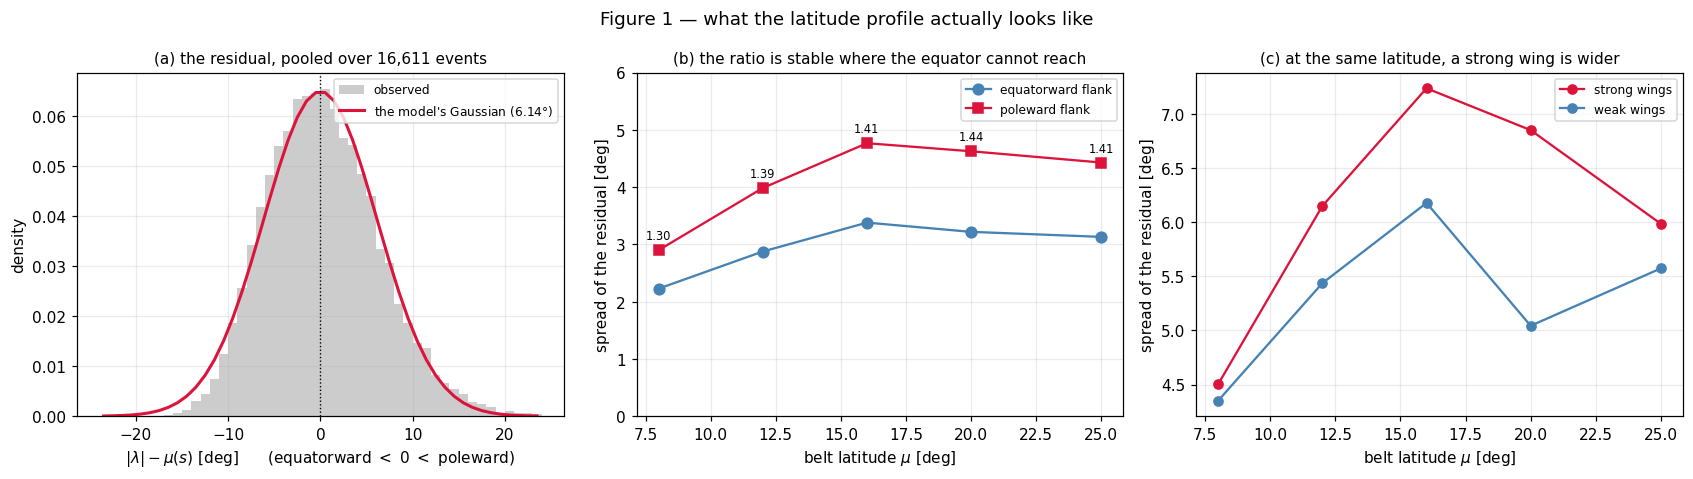

In [24]:
# Given: Figure 1 — the latitude profile is not symmetric, and not because of the equator.
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))

ax = axes[0]
edges = np.arange(-24, 24.5, 1.0)
ax.hist(RESIDUAL, bins=edges, color="0.8", edgecolor="none", density=True, label="observed")
centres = 0.5 * (edges[1:] + edges[:-1])
sd = RESIDUAL.std(ddof=1)
ax.plot(centres, np.exp(-centres ** 2 / (2 * sd ** 2)) / (sd * np.sqrt(2 * np.pi)),
        color="crimson", lw=2, label=f"the model's Gaussian ({sd:.2f}$°$)")
ax.axvline(0.0, color="k", lw=0.9, ls=":")
ax.set_xlabel(r"$|\lambda| - \mu(s)$ [deg]      (equatorward $<$ 0 $<$ poleward)")
ax.set_ylabel("density")
ax.set_title("(a) the residual, pooled over 16,611 events", fontsize=10)
ax.legend(fontsize=8)

ax = axes[1]
mids = [0.5 * (lo + hi) for lo, hi in BANDS]
below = [RESIDUAL[(MU_AT_EVENT >= lo) & (MU_AT_EVENT < hi) & (RESIDUAL < 0)].std(ddof=1)
         for lo, hi in BANDS]
above = [RESIDUAL[(MU_AT_EVENT >= lo) & (MU_AT_EVENT < hi) & (RESIDUAL > 0)].std(ddof=1)
         for lo, hi in BANDS]
ax.plot(mids, below, "o-", color="steelblue", ms=7, label="equatorward flank")
ax.plot(mids, above, "s-", color="crimson", ms=7, label="poleward flank")
for x, b, a in zip(mids, below, above):
    ax.annotate(f"{a / b:.2f}", (x, a), fontsize=7.5, xytext=(0, 7), ha="center",
                textcoords="offset points")
ax.set_xlabel(r"belt latitude $\mu$ [deg]")
ax.set_ylabel("spread of the residual [deg]")
ax.set_ylim(0, 6)
ax.set_title("(b) the ratio is stable where the equator cannot reach", fontsize=10)
ax.legend(fontsize=8)

ax = axes[2]
strong = [h for h in DEV_HEMICYCLES if AREA_AMPLITUDE[h] >= WINGS["A"].median()]
weak = [h for h in DEV_HEMICYCLES if h not in strong]
for group, name, colour in ((strong, "strong wings", "crimson"), (weak, "weak wings", "steelblue")):
    lat_g = np.concatenate([EVENTS[h][0] for h in group])
    s_g = np.concatenate([EVENTS[h][1] for h in group])
    mu_g = DRIFTS[BASELINE_SPEC["drift"]]["fn"](s_g, DRIFT_P)
    spread = [(lat_g - mu_g)[(mu_g >= lo) & (mu_g < hi)].std(ddof=1) for lo, hi in BANDS]
    ax.plot(mids, spread, "o-", color=colour, ms=6, label=name)
ax.set_xlabel(r"belt latitude $\mu$ [deg]")
ax.set_ylabel("spread of the residual [deg]")
ax.set_title("(c) at the same latitude, a strong wing is wider", fontsize=10)
ax.legend(fontsize=8)
fig.suptitle("Figure 1 — what the latitude profile actually looks like")
plt.tight_layout()
plt.show()

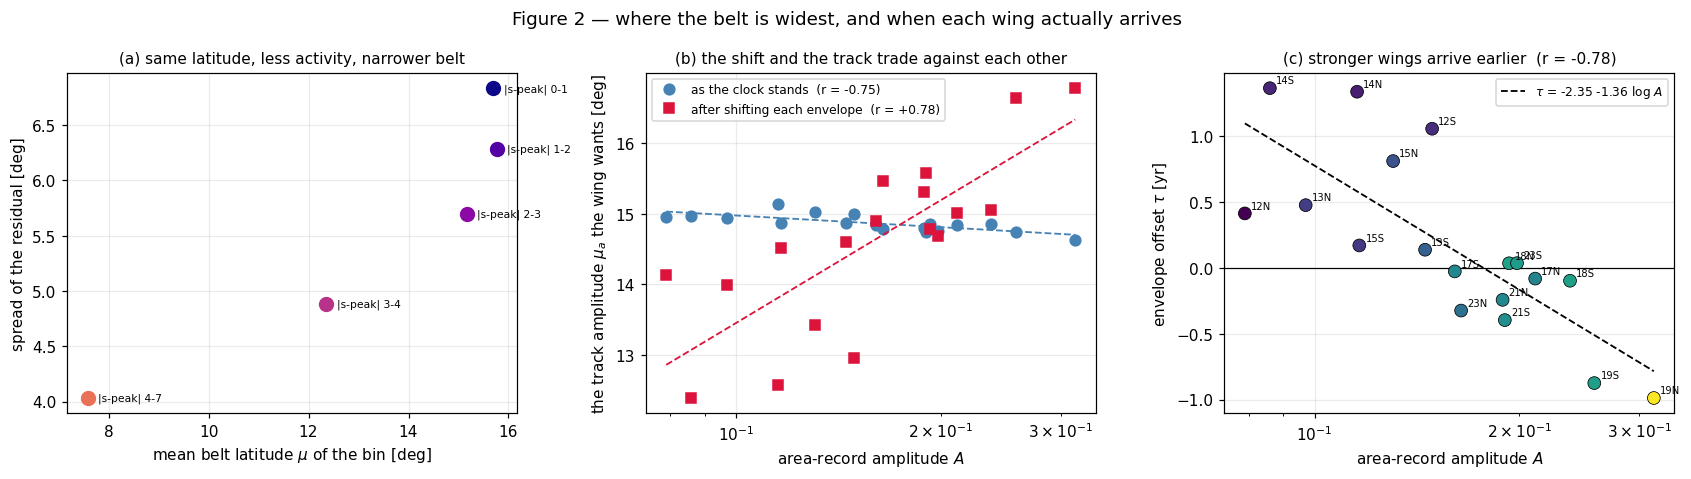

In [25]:
# Given: Figure 2 — the width tracks the activity, not the latitude; and the clock degeneracy.
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))

ax = axes[0]
peak_s = S_A + (BASE_FIT["shared"]["shape_shared"][0] - 1) * BASE_FIT["shared"]["shape_shared"][1]
for lo, hi in ((0.0, 1.0), (1.0, 2.0), (2.0, 3.0), (3.0, 4.5), (4.5, 7.0)):
    m = (np.abs(ALL_S - peak_s) >= lo) & (np.abs(ALL_S - peak_s) < hi)
    ax.plot([MU_AT_EVENT[m].mean()], [RESIDUAL[m].std(ddof=1)], "o", ms=9,
            color=plt.cm.plasma(lo / 7.0))
    ax.annotate(f"|s-peak| {lo:.0f}-{hi:.0f}", (MU_AT_EVENT[m].mean(), RESIDUAL[m].std(ddof=1)),
                fontsize=7, xytext=(7, -2), textcoords="offset points")
ax.set_xlabel(r"mean belt latitude $\mu$ of the bin [deg]")
ax.set_ylabel("spread of the residual [deg]")
ax.set_title("(a) same latitude, less activity, narrower belt", fontsize=10)

ax = axes[1]
logA = np.log(WINGS["A"])
for column, colour, marker, name in (("mu_a_raw", "steelblue", "o", "as the clock stands"),
                                     ("mu_a_shifted", "crimson", "s", "after shifting each envelope")):
    ax.plot(WINGS["A"], WINGS[column], marker, color=colour, ms=7,
            label=f"{name}  (r = {np.corrcoef(logA, WINGS[column])[0, 1]:+.2f})")
    fit = np.polyfit(logA, WINGS[column], 1)
    line = np.linspace(WINGS["A"].min(), WINGS["A"].max(), 20)
    ax.plot(line, np.polyval(fit, np.log(line)), color=colour, lw=1.2, ls="--")
ax.set_xscale("log")
ax.set_xlabel("area-record amplitude $A$")
ax.set_ylabel(r"the track amplitude $\mu_a$ the wing wants [deg]")
ax.set_title("(b) the shift and the track trade against each other", fontsize=10)
ax.legend(fontsize=8)

ax = axes[2]
ax.scatter(WINGS["A"], WINGS["tau"], s=70, c=WINGS["n"], cmap="viridis",
           edgecolors="k", linewidths=0.5, zorder=3)
fit = np.polyfit(logA, WINGS["tau"], 1)
line = np.linspace(WINGS["A"].min(), WINGS["A"].max(), 20)
ax.plot(line, np.polyval(fit, np.log(line)), "k--", lw=1.2,
        label=f"$\\tau$ = {fit[1]:+.2f} {fit[0]:+.2f} log $A$")
for label, row in WINGS.iterrows():
    ax.annotate(label, (row["A"], row["tau"]), fontsize=6.5, xytext=(4, 3),
                textcoords="offset points")
ax.axhline(0.0, color="k", lw=0.8)
ax.set_xscale("log")
ax.set_xlabel("area-record amplitude $A$")
ax.set_ylabel(r"envelope offset $\tau$ [yr]")
ax.set_title(f"(c) stronger wings arrive earlier  (r = {np.corrcoef(logA, WINGS['tau'])[0, 1]:+.2f})",
             fontsize=10)
ax.legend(fontsize=8)
fig.suptitle("Figure 2 — where the belt is widest, and when each wing actually arrives")
plt.tight_layout()
plt.show()

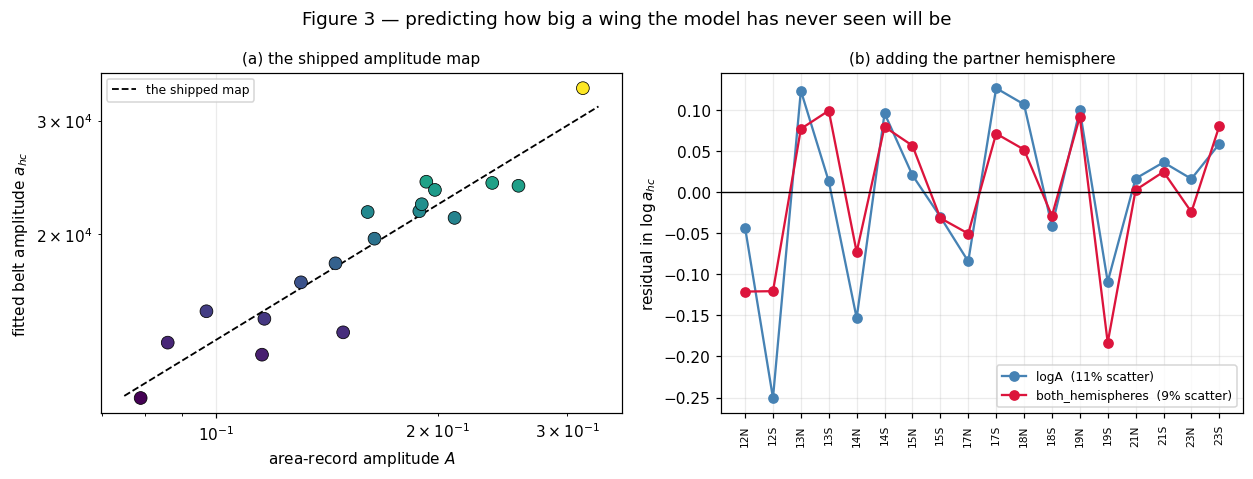

In [26]:
# Given: Figure 3 — the one quantity a held-out wing has to be given, and how well it can be given.
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))

ax = axes[0]
ax.scatter(WINGS["A"], WINGS["a_hc"], s=70, c=WINGS["n"], cmap="viridis",
           edgecolors="k", linewidths=0.5, zorder=3)
fit = np.polyfit(logA, np.log(WINGS["a_hc"]), 1)
line = np.linspace(WINGS["A"].min() * 0.95, WINGS["A"].max() * 1.05, 20)
ax.plot(line, np.exp(np.polyval(fit, np.log(line))), "k--", lw=1.2, label="the shipped map")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("area-record amplitude $A$")
ax.set_ylabel(r"fitted belt amplitude $a_{hc}$")
ax.set_title("(a) the shipped amplitude map", fontsize=10)
ax.legend(fontsize=8)

ax = axes[1]
target = np.log(WINGS["a_hc"].to_numpy())
for kind, colour in (("logA", "steelblue"), ("both_hemispheres", "crimson")):
    design = amplitude_design(DEV_HEMICYCLES, AREA_AMPLITUDE, kind)
    beta = np.linalg.lstsq(design, target, rcond=None)[0]
    resid = target - design @ beta
    scatter = float(np.sqrt(resid @ resid / (len(target) - design.shape[1])))
    ax.plot(np.arange(len(DEV_HEMICYCLES)), resid, "o-", color=colour, ms=6,
            label=f"{kind}  ({100 * scatter:.0f}% scatter)")
ax.axhline(0.0, color="k", lw=0.9)
ax.set_xticks(np.arange(len(DEV_HEMICYCLES)))
ax.set_xticklabels(DEV_HEMICYCLES, rotation=90, fontsize=7)
ax.set_ylabel(r"residual in $\log a_{hc}$")
ax.set_title("(b) adding the partner hemisphere", fontsize=10)
ax.legend(fontsize=8)
fig.suptitle("Figure 3 — predicting how big a wing the model has never seen will be")
plt.tight_layout()
plt.show()

---
## 4 · The four knobs

| knob | the claim about the Sun | parameters | predictable because |
|---|---|---|---|
| `shift = from_amplitude` | a stronger cycle's activity arrives earlier relative to where its belt is | 2 global | the shift is a function of the wing's amplitude, which comes from the area record |
| `profile = asymmetric` | the emerging band is broader on its poleward flank than its equatorward one | 1 global | it is a shared shape with no per-wing freedom at all |
| `width = instantaneous` | the band is widest when it is strongest, within a cycle and not only between cycles | 2 global | same form as the rule it replaces, evaluated at `a_hc·g(s)` |
| `amplitude_map = both_hemispheres` ⚠️ | a wing's size is better predicted from both hemispheres' area records than from its own | 1 extra regressor | **ruled out by decision #8** — measured below to cost the decision, never shipped |

**The fourth knob is measured and then discarded on principle.** Decision #8 decouples the
hemispheres: nothing that produces one wing may read the other's record, however observable that
record is. It is still scored in section 5, because the decision is costed against a measurement
rather than an assumption, and it is excluded from the search in section 6 and from everything
this notebook ships. Read its row as the price of the decision, not as a candidate.

Two of the others are *replacements* rather than additions, and that matters for reading the table below.
`width = instantaneous` occupies the same stage as `width = amplitude`, so adopting it means giving the
incumbent's width rule up — the two can never both be in a model. `amplitude_map` changes nothing about
the fitted model at all; it changes only what a held-out wing is told about its own size.

The shift is the one to watch for trouble. It makes the time profile depend on `a_hc`, which the
block-coordinate fitter re-estimates on every sweep, so there is a feedback loop that the other three do
not have. If the per-sweep likelihood is still moving at three sweeps, raise it.

In [27]:
# Given: the catalog, now that the four are in it.
for stage, values in KNOB_REGISTRY.items():
    marker = "" if len(values) > 1 else "   <- one value, so not a knob"
    print(f"   {stage:14s} {len(values):2d}  {', '.join(values)}{marker}")
print(f"\nbaseline spec: " + ", ".join(f"{k}={v}" for k, v in BASELINE_SPEC.items()))
print(f"the whole grid is now {grid_size():,} specs")

   shape           5  gamma, lognormal, weibull, two_sided, gaussian
   pooling         4  shared, hemisphere, wing_rise, wing_all
   shift           3  none, from_amplitude, from_amplitude_1p
   drift           3  exponential, linear, hyperbolic
   profile         2  gaussian, asymmetric
   width           6  constant, amplitude, latitude, piecewise, combo, instantaneous
   gate            3  none, tanh_mu, tanh_x
   emission        2  threshold, direct
   amplitude_map   2  logA, both_hemispheres

baseline spec: shape=gamma, pooling=shared, shift=none, drift=exponential, profile=gaussian, width=constant, gate=none, emission=threshold, amplitude_map=logA
the whole grid is now 25,920 specs


---
## 5 · The ablation

Everything is paired against **the incumbent**, not against the baseline. A knob's worth depends on what
is already in the model, and the question here is not "does this help a bare belt?" but "does this beat
the best thing we have?"

- **Stage A — forward.** Each knob added to, or swapped into, the incumbent on its own. *Which help?*
- **Stage B — combine.** Everything from Stage A whose gain cleared its own standard error, together.
- **Stage C — backward.** Each knob in the combined model dropped in turn, including the incumbent's own
  two. *Is each still earning its parameter now that the others are there?*

Stage C is the one that cannot be skipped. Forward selection alone cannot see a knob that has been made
redundant by the knobs adopted after it, and two of these are expected to overlap: `instantaneous`
generalizes `amplitude`, and the shift is partly degenerate with the track amplitude, as Figure 2(b)
showed.

### Predictions, recorded before the runs

1. The shift is the largest single gain, and after adopting it the fitted `mu_a` rises from 14.59°
   towards 15.5–16°, because the degeneracy in Figure 2(b) has to go somewhere.
2. The asymmetric profile is second and is close to orthogonal to everything else.
3. `instantaneous` beats `amplitude`, but by less than its own standard error once the shift is in, since
   part of what the amplitude width was doing was absorbing the misplacement.
4. The amplitude map is worth under 0.1 nats and may not clear its standard error at all.
   (Scored for the record, but the knob is ruled out by decision #8 whatever it measures.)

In [28]:
# Given: the incumbent, and the four candidates on top of it.
INCUMBENT = spec_of(shape="two_sided", width="amplitude")
NEW_KNOBS = {"shift": "from_amplitude", "profile": "asymmetric",
             "width": "instantaneous", "amplitude_map": "both_hemispheres"}
QUESTIONS = {
    "shift": "does a stronger wing's activity arrive earlier than the shared envelope puts it?",
    "profile": "is the band broader on its poleward flank than its equatorward one?",
    "width": "is the band widest when it is strongest, within a cycle and not only between cycles?",
    "amplitude_map": "is a wing's size better predicted from both hemispheres' area records?",
}


def score(spec, question=""):
    started = time.time()
    cached = (CACHE / f"{variant_name(spec)}.json").exists()
    result = run_variant(spec, question)
    print(f"   {variant_name(spec):62s} {'cached' if cached else f'{time.time() - started:5.0f} s'}   "
          f"held out {rows_of(result)[f'nll/yr ({HEADLINE})'].mean():8.3f}", flush=True)
    return result


def against(result, reference):
    stats = paired_stats(result, reference)
    return dict(gain=-stats["mean"], se=stats["se"], median=-stats["median"],
                better=f"{stats['better']}/{stats['n']}",
                clears=bool(-stats["mean"] > stats["se"]))


print("the incumbent, through this notebook's own copy of the machinery:")
INCUMBENT_RESULT = score(INCUMBENT, "the best model on the student board")

print("\nStage A — one knob at a time, on top of the incumbent:")
stage_a = {}
for stage, value in NEW_KNOBS.items():
    result = score({**INCUMBENT, stage: value}, QUESTIONS[stage])
    stage_a[stage] = dict(value=value, result=result, **against(result, INCUMBENT_RESULT))

table_a = pd.DataFrame(stage_a).T[["value", "gain", "se", "median", "better", "clears"]]
print()
print(table_a.to_string(float_format=lambda v: f"{v:9.4f}"))

the incumbent, through this notebook's own copy of the machinery:
   shape-two_sided__width-amplitude                               cached   held out  -26.289



Stage A — one knob at a time, on top of the incumbent:
   shape-two_sided__shift-from_amplitude__width-amplitude         cached   held out  -28.074


   profile-asymmetric__shape-two_sided__width-amplitude           cached   held out  -26.528


   shape-two_sided__width-instantaneous                           cached   held out  -26.407


   amplitude_map-both_hemispheres__shape-two_sided__width-amplitude cached   held out  -26.327



                          value      gain        se    median better clears
shift            from_amplitude    1.7844    0.8804    0.4257  11/18   True
profile              asymmetric    0.2384    0.1049    0.2597  12/18   True
width             instantaneous    0.1177    0.1689    0.1214  10/18  False
amplitude_map  both_hemispheres    0.0376    0.1370    0.0513  13/18  False


In [29]:
# Given: Stage B — everything that cleared its own standard error, together.
ADOPTED = [stage for stage, row in stage_a.items() if row["clears"]]
COMBINED = {**INCUMBENT, **{stage: NEW_KNOBS[stage] for stage in ADOPTED}}
print(f"adopted from Stage A: {', '.join(ADOPTED) if ADOPTED else 'nothing'}")
print(f"combined spec: " + ", ".join(f"{k}={v}" for k, v in COMBINED.items()
                                     if v != BASELINE_SPEC[k]))
print()
COMBINED_RESULT = score(COMBINED, "every knob that cleared its standard error, together")
combined_gain = against(COMBINED_RESULT, INCUMBENT_RESULT)
print(f"\ncombined against the incumbent: {combined_gain['gain']:+.4f} +/- {combined_gain['se']:.4f}, "
      f"median {combined_gain['median']:+.4f}, better in {combined_gain['better']}")
print(f"sum of the Stage A gains that went in: "
      f"{sum(stage_a[s]['gain'] for s in ADOPTED):+.4f}")

adopted from Stage A: shift, profile
combined spec: shape=two_sided, shift=from_amplitude, profile=asymmetric, width=amplitude

   profile-asymmetric__shape-two_sided__shift-from_amplitude__width-amplitude cached   held out  -28.388



combined against the incumbent: +2.0988 +/- 0.9142, median +0.9161, better in 14/18
sum of the Stage A gains that went in: +2.0228


In [30]:
# Given: Stage C — drop each knob in the combined model in turn, the incumbent's own included.
print("Stage C — backward, dropping one knob at a time out of the combined model:")
stage_c = {}
for stage, value in COMBINED.items():
    if value == BASELINE_SPEC[stage]:
        continue
    dropped = {**COMBINED, stage: BASELINE_SPEC[stage]}
    result = score(dropped, f"what the combined model loses without {stage}={value}")
    worse = against(COMBINED_RESULT, result)        # combined minus the model without this knob
    stage_c[f"{stage}={value}"] = dict(
        origin="new" if NEW_KNOBS.get(stage) == value else "incumbent",
        contributes=worse["gain"], se=worse["se"], median=worse["median"], better=worse["better"],
        clears=worse["clears"])

table_c = pd.DataFrame(stage_c).T[["origin", "contributes", "se", "median", "better", "clears"]]
print()
print(table_c.to_string(float_format=lambda v: f"{v:9.4f}"))
print("\n`contributes` is what the combined model would lose if that knob were removed — a knob that fails")
print("to clear its standard error here is being carried by the others and is spending a parameter for")
print("nothing, however well it did in Stage A.")

Stage C — backward, dropping one knob at a time out of the combined model:
   profile-asymmetric__shift-from_amplitude__width-amplitude      cached   held out  -28.357


   profile-asymmetric__shape-two_sided__width-amplitude           cached   held out  -26.528


   shape-two_sided__shift-from_amplitude__width-amplitude         cached   held out  -28.074


   profile-asymmetric__shape-two_sided__shift-from_amplitude      cached   held out  -27.864



                         origin contributes        se    median better clears
shape=two_sided       incumbent      0.0315    0.0425    0.0046   9/18  False
shift=from_amplitude        new      1.8605    0.8852    0.4789  11/18   True
profile=asymmetric          new      0.3144    0.1099    0.2651  12/18   True
width=amplitude       incumbent      0.5238    0.2262    0.1587  14/18   True

`contributes` is what the combined model would lose if that knob were removed — a knob that fails
to clear its standard error here is being carried by the others and is spending a parameter for
nothing, however well it did in Stage A.


In [31]:
# Given: the model Stage C leaves standing, and handed to the search in section 6.
SURVIVING = [stage for stage, value in COMBINED.items()
             if value != BASELINE_SPEC[stage] and stage_c[f"{stage}={value}"]["clears"]]
SURVIVING = [stage for stage in SURVIVING if (stage, COMBINED[stage]) not in RULED_OUT]
PRUNED = {**BASELINE_SPEC, **{stage: COMBINED[stage] for stage in SURVIVING}}
print(f"knobs that survive Stage C: {', '.join(SURVIVING)}")
for stage, value in sorted(RULED_OUT):
    print(f"   {stage}={value} is dropped here whatever it scored: decision #8, the hemispheres are")
    print("      decoupled. Section 5 above is what the decision is costed against.")
print(f"pruned spec: " + ", ".join(f"{k}={v}" for k, v in PRUNED.items() if v != BASELINE_SPEC[k]))
PRUNED_RESULT = COMBINED_RESULT if PRUNED == COMBINED else score(PRUNED, "what survives the backward pass")

knobs that survive Stage C: shift, profile, width
   amplitude_map=both_hemispheres is dropped here whatever it scored: decision #8, the hemispheres are
      decoupled. Section 5 above is what the decision is costed against.
pruned spec: shift=from_amplitude, profile=asymmetric, width=amplitude
   profile-asymmetric__shift-from_amplitude__width-amplitude      cached   held out  -28.357


---
## 6 · The full search

Stages A to C explored one neighbourhood: the knobs we arrived with, on top of the model we arrived with.
That is not the same as the best model this catalog can express, and Stage C has already shown why not —
`shape=two_sided` was worth +0.18 when it was adopted and +0.03 once the shift was in, because it had
been standing in for a degree of freedom the model lacked. **Every other stage was ranked the same way,
against a baseline that still contained the misplacement, so every other ranking is suspect too.**

So this section does the honest thing and searches properly: **coordinate ascent over every stage, until
a whole round changes nothing.** One stage at a time, try every value it can take, adopt the best if its
gain clears its own standard error, move on. Repeat.

Three properties are worth naming, because they are why this subsumes the three stages above:

- *It contains the backward pass.* Reverting a knob to its baseline value is just another value of that
  stage, so a knob that has been made redundant will be dropped automatically when its stage comes round.
- *It contains the forward pass.* Every unexplored value on every stage gets tried against the current
  best, not against a stale reference.
- *It is still not exhaustive.* Coordinate ascent finds a local optimum of a noisy objective. The whole
  grid is far larger, and a pair of knobs that only help together will be missed. Section 8 says what
  that costs.

The acceptance rule is the week's own convention: a gain smaller than its own standard error is a tie,
and a tie is not adopted. The two unranked pooling plans are excluded from the search entirely — they are
bounds, not predictions, and nothing that cannot predict is allowed to win.

In [32]:
# Given: coordinate ascent over the catalog.
SEARCH_STAGES = [stage for stage, values in KNOB_REGISTRY.items() if len(values) > 1]
EXCLUDED = {("pooling", "wing_rise"), ("pooling", "wing_all")} | RULED_OUT
print(f"searching over {len(SEARCH_STAGES)} stages: {', '.join(SEARCH_STAGES)}")
print(f"excluded from the search: {', '.join(f'{a}={b}' for a, b in sorted(EXCLUDED))}")
print("   pooling bounds cannot predict a held-out wing; the cross-hemisphere amplitude map is ruled")
print("   out by decision #8, which costs it against the measurement in section 5 rather than assuming.\n")


def search(start, max_rounds=4):
    """Try every value of every stage against the current best; adopt what clears its standard error."""
    current, trail = dict(start), []
    for round_index in range(1, max_rounds + 1):
        print(f"round {round_index}")
        improved = False
        for stage in SEARCH_STAGES:
            reference = run_variant(current)
            attempts = []
            for value in KNOB_REGISTRY[stage]:
                if value == current[stage] or (stage, value) in EXCLUDED:
                    continue
                result = score({**current, stage: value},
                               f"round {round_index}: {stage}={value}")
                stats = paired_stats(result, reference)
                attempts.append(dict(round=round_index, stage=stage, value=value,
                                     gain=-stats["mean"], se=stats["se"],
                                     median=-stats["median"],
                                     better=f"{stats['better']}/{stats['n']}", adopted=False))
            winners = [a for a in attempts if a["gain"] > a["se"]]
            if winners:
                best = max(winners, key=lambda a: a["gain"])
                best["adopted"] = True
                current[stage] = best["value"]
                improved = True
                print(f"      -> adopt {stage}={best['value']}  "
                      f"({best['gain']:+.4f} +/- {best['se']:.4f})", flush=True)
            trail.extend(attempts)
        if not improved:
            print(f"   round {round_index} changed nothing: the search has converged")
            break
    return current, pd.DataFrame(trail)


BEST, TRAIL = search(PRUNED)
SEARCH_FINAL, SEARCH_RESULT = BEST, run_variant(BEST)
print(f"\nthe search ends at: " + ", ".join(f"{k}={v}" for k, v in SEARCH_FINAL.items()
                                            if v != BASELINE_SPEC[k]))

searching over 9 stages: shape, pooling, shift, drift, profile, width, gate, emission, amplitude_map
excluded from the search: amplitude_map=both_hemispheres, pooling=wing_all, pooling=wing_rise
   pooling bounds cannot predict a held-out wing; the cross-hemisphere amplitude map is ruled
   out by decision #8, which costs it against the measurement in section 5 rather than assuming.

round 1
   profile-asymmetric__shape-lognormal__shift-from_amplitude__width-amplitude cached   held out  -28.308


   profile-asymmetric__shape-weibull__shift-from_amplitude__width-amplitude cached   held out  -28.397


   profile-asymmetric__shape-two_sided__shift-from_amplitude__width-amplitude cached   held out  -28.388


   profile-asymmetric__shape-gaussian__shift-from_amplitude__width-amplitude cached   held out  -27.518


   pooling-hemisphere__profile-asymmetric__shift-from_amplitude__width-amplitude cached   held out  -28.166


   profile-asymmetric__width-amplitude                            cached   held out  -26.342


... (48 outputs left out)

   profile-asymmetric__shift-from_amplitude_1p__width-instantaneous cached   held out  -28.679


   gate-tanh_mu__profile-asymmetric__shift-from_amplitude_1p__width-instantaneous cached   held out  -28.876


   emission-direct__gate-tanh_x__profile-asymmetric__shift-from_amplitude_1p__width-instantaneous cached   held out  -28.698


   round 3 changed nothing: the search has converged

the search ends at: shift=from_amplitude_1p, profile=asymmetric, width=instantaneous, gate=tanh_x


### 6b · The two shifts, side by side

`shift` can be written two ways. `from_amplitude` spends two parameters, `tau = c0 + c1 ln(a/a_ref)`;
`from_amplitude_1p` spends one, dropping the constant. They are not independent hypotheses. `tau`
enters the model only through `s - tau - S_A`, and that one expression feeds **two** things: the time
profile `g`, whose gamma peak sits at `(k-1)theta`, and the gate, which is pinned to envelope time `x`
and cuts at `x_cut`. A constant added to `tau` is therefore exactly a joint translation of the
envelope peak and the gate cut — and both of those are already free parameters. `c0` is a third name
for a position the model can already state twice, which makes it a **gauge freedom rather than a
weak parameter**: not merely hard to identify, but redundant by construction.

**A coordinate search cannot find this by itself.** It moves one *stage* at a time and takes each
stage's values as given, so a redundant parameter *inside* a value it has already adopted is invisible
to it — not because the search is weak, but because reparameterising a stage is not a move it has. The
one-parameter form had to be **added to the catalog** by hand before the search could choose it. Once
it was there, the search picked it up as an ordinary stage move and adopted it. That is the division of
labour worth naming: the human supplies the reparameterisation, the search supplies the verdict.

The prompt came from outside this notebook. A Week 04 student group reached the same model from a
literature review using **one** amplitude coefficient where we spent two, which is what made us look.
See `assessment/week_04/contributions.ipynb` section 4b.

In [33]:
# Given: both forms of the shift, scored against each other on the same folds. This prints whichever way
# the search went, so the comparison stays visible instead of being implied by the winner.
FINAL, FINAL_RESULT = SEARCH_FINAL, SEARCH_RESULT
SHIFT_FORMS = ("from_amplitude", "from_amplitude_1p")
if FINAL.get("shift") in SHIFT_FORMS:
    pair = {}
    for form in SHIFT_FORMS:
        spec = dict(FINAL, shift=form)
        pair[form] = run_variant(spec, "the shift, with and without its constant")
    rich, lean = pair["from_amplitude"], pair["from_amplitude_1p"]
    verdict = against(lean, rich)
    c0_fitted, c1_fitted = rich["shared"]["stages"]["shift"]
    print(f"the two-parameter form fits c0 = {c0_fitted:+.4f} yr and c1 = {c1_fitted:+.4f} yr per "
          f"e-fold of amplitude.")
    print(f"the constant is {abs(c0_fitted / c1_fitted):.0%} the size of the coefficient — a hint, not "
          f"evidence. The evidence is below.\n")
    for label, result in (("c0 free  (from_amplitude)", rich), ("c0 = 0   (from_amplitude_1p)", lean)):
        print(f"   {label:30s} {rows_of(result)[f'nll/yr ({HEADLINE})'].mean():9.4f}  "
              f"{result['n_params']:2d} parameters")
    print(f"\n   dropping c0: {verdict['gain']:+.4f} +/- {verdict['se']:.4f} nats, better on "
          f"{verdict['better']} wings")
    print(f"   c1 moves by {abs(lean['shared']['stages']['shift'][0] - c1_fitted):.4f} when c0 goes, "
          f"which is what an unidentified direction looks like.")
    # where c0 went: if it really is a joint translation, the two positions it is redundant with should
    # each move by about +c0 when it is removed. They do, which is the demonstration rather than the claim.
    peak = lambda sh: (sh["shape"]["0"] - 1.0) * sh["shape"]["1"]     # the gamma's mode, in envelope time
    if FINAL.get("shape") == "gamma" and FINAL.get("gate", "none").startswith("tanh"):
        print(f"\n   where c0 went, now that it is gone (both are positions in envelope time):")
        print(f"      c0 removed                  {c0_fitted:+.4f} yr")
        print(f"      gamma peak (k-1)*theta      {peak(lean['shared']) - peak(rich['shared']):+.4f} yr  "
              f"({peak(rich['shared']):.4f} -> {peak(lean['shared']):.4f})")
        print(f"      gate cut x_cut              "
              f"{lean['shared']['stages']['gate'][0] - rich['shared']['stages']['gate'][0]:+.4f} yr  "
              f"({rich['shared']['stages']['gate'][0]:.4f} -> "
              f"{lean['shared']['stages']['gate'][0]:.4f})")
        print("      Both absorbed it. The likelihood barely moved because nothing was lost: the model")
        print("      could already say what c0 was saying, in two places that were paying for themselves.")
    cheaper = min(pair.values(), key=lambda r: r["n_params"])
    # not "better" — *not worse*, one parameter cheaper. A tie in score is a win on parsimony.
    assert FINAL["shift"] == cheaper["spec"]["shift"] or verdict["gain"] <= -verdict["se"], (
        "the cheaper shift is not worse, so the search should have taken it; it did not.")
    print(f"\n   the search took {FINAL['shift']}, and it is the cheaper of the two.")

print(f"\nthe model this notebook ends on: " + ", ".join(f"{k}={v}" for k, v in FINAL.items()
                                                         if v != BASELINE_SPEC[k]))

# ── the champion, declared ────────────────────────────────────────────────────────────────────────
# This notebook is the program's single source of truth for the best parametric model, and it is a
# LIVING record: when a student submission or a later measurement improves the model, this is where the
# change lands and this line changes with it. Other weeks copy the spec rather than re-running the
# search, so it is written out explicitly here for them to copy, and `tools/check_champion.py` checks
# that every copy still agrees. The assert is what keeps the declaration honest: if the search or
# section 6b ends somewhere else, this cell fails rather than letting the declaration go stale.
CHAMPION_SPEC = dict(BASELINE_SPEC, shift="from_amplitude_1p", profile="asymmetric",
                     width="instantaneous", gate="tanh_x")
assert FINAL == CHAMPION_SPEC, (
    f"the declared champion no longer matches what this notebook ends on.\n"
    f"  declared : {variant_name(CHAMPION_SPEC)}\n"
    f"  ends on  : {variant_name(FINAL)}\n"
    f"Update CHAMPION_SPEC above, then run tools/check_champion.py to find the copies that need it.")
print(f"declared champion: {variant_name(CHAMPION_SPEC)} "
      f"({FINAL_RESULT['n_params']} parameters, {Model(FINAL).n_q} shared)")

the two-parameter form fits c0 = +0.1876 yr and c1 = -2.3465 yr per e-fold of amplitude.
the constant is 8% the size of the coefficient — a hint, not evidence. The evidence is below.

   c0 free  (from_amplitude)       -28.9950  30 parameters
   c0 = 0   (from_amplitude_1p)    -29.0226  29 parameters

   dropping c0: +0.0275 +/- 0.0157 nats, better on 10/18 wings
   c1 moves by 0.0040 when c0 goes, which is what an unidentified direction looks like.

   where c0 went, now that it is gone (both are positions in envelope time):
      c0 removed                  +0.1876 yr
      gamma peak (k-1)*theta      +0.2111 yr  (5.4939 -> 5.7050)
      gate cut x_cut              +0.2318 yr  (12.3200 -> 12.5518)
      Both absorbed it. The likelihood barely moved because nothing was lost: the model
      could already say what c0 was saying, in two places that were paying for themselves.

   the search took from_amplitude_1p, and it is the cheaper of the two.

the model this notebook ends on: shift

In [34]:
# Given: the board for everything this notebook has run, the search included. It sits here rather than
# before section 6 so that it sees the variants the search itself produced; placed earlier it reported a
# best row that the next section then overturned.
board = []
for name, result in sorted(load_cached().items()):
    stats = against(result, INCUMBENT_RESULT)
    barred = any(result["spec"].get(stage) == value for stage, value in RULED_OUT)
    board.append(dict(variant=name, params=result["n_params"],
                      held_nll=float(rows_of(result)[f"nll/yr ({HEADLINE})"].mean()),
                      vs_incumbent=stats["gain"], se=stats["se"], median=stats["median"],
                      better=stats["better"],
                      ks=float(rows_of(result)[f"ks ({HEADLINE})"].median()),
                      seconds=round(result["seconds"]),
                      shippable="" if barred else "yes"))
BOARD = pd.DataFrame(board).set_index("variant").sort_values("vs_incumbent", ascending=False)
print()
print(BOARD.to_string(float_format=lambda v: f"{v:9.4f}"))
barred_rows = BOARD[BOARD["shippable"] == ""]
if len(barred_rows):
    print(f"\n{len(barred_rows)} of {len(BOARD)} rows are not shippable: they read the opposite")
    print("hemisphere's record, which decision #8 rules out. They are scored and listed because the")
    print("decision is costed against them, and the best of them is NOT the model this notebook ships.")
    print(f"best shippable: {BOARD[BOARD['shippable'] == 'yes'].index[0]}")


                                                                                                                                    params  held_nll  vs_incumbent        se    median better        ks  seconds shippable
variant                                                                                                                                                                                                                   
amplitude_map-both_hemispheres__profile-asymmetric__shape-two_sided__shift-from_amplitude__width-instantaneous                          29  -29.1849        2.8956    1.1029    1.7608  14/18    0.0391      327          
amplitude_map-both_hemispheres__emission-direct__profile-asymmetric__shape-two_sided__shift-from_amplitude__width-instantaneous         29  -29.1368        2.8475    1.0786    1.6852  14/18    0.0394      157          
amplitude_map-both_hemispheres__profile-asymmetric__shift-from_amplitude__width-instantaneous                              

In [35]:
# Given: everything the search tried, and what it did with it.
print(TRAIL[TRAIL["adopted"]].to_string(index=False, float_format=lambda v: f"{v:9.4f}")
      if TRAIL["adopted"].any() else "   the search adopted nothing beyond the pruned model")
print()
print("the five closest calls it declined:")
declined = TRAIL[~TRAIL["adopted"]].assign(shortfall=lambda d: d["se"] - d["gain"])
print(declined.nsmallest(5, "shortfall")[["round", "stage", "value", "gain", "se", "better"]]
      .to_string(index=False, float_format=lambda v: f"{v:9.4f}"))
print(f"\n{len(TRAIL)} candidates evaluated over {TRAIL['round'].max()} round(s); "
      f"{len(load_cached())} variants now in the cache")

final_vs_incumbent = against(FINAL_RESULT, INCUMBENT_RESULT)
final_vs_pruned = against(FINAL_RESULT, PRUNED_RESULT)
print(f"\nthe search's model against the pruned one : {final_vs_pruned['gain']:+.4f} "
      f"+/- {final_vs_pruned['se']:.4f}")
print(f"the search's model against the incumbent  : {final_vs_incumbent['gain']:+.4f} "
      f"+/- {final_vs_incumbent['se']:.4f}, median {final_vs_incumbent['median']:+.4f}, "
      f"better in {final_vs_incumbent['better']}")

 round stage             value      gain        se    median better  adopted
     1 width     instantaneous    0.3794    0.1582    0.4224  14/18     True
     1  gate            tanh_x    0.2590    0.0567    0.1961  16/18     True
     2 shift from_amplitude_1p    0.0275    0.0157    0.0053  10/18     True

the five closest calls it declined:
 round stage          value      gain        se better
     1  gate        tanh_mu    0.1228    0.0695  14/18
     1 width          combo    0.0613    0.0297  13/18
     1 shape      two_sided    0.0315    0.0425   9/18
     3 shift from_amplitude   -0.0275    0.0157   8/18
     2 shape      lognormal   -0.0121    0.0334  10/18



54 candidates evaluated over 3 round(s); 82 variants now in the cache

the search's model against the pruned one : +0.6659 +/- 0.1772
the search's model against the incumbent  : +2.7333 +/- 1.0263, median +1.4480, better in 15/18


In [36]:
# Given: is the fit converged? The shift makes tau depend on a_hc, which the block-coordinate fitter
# re-estimates every sweep — a feedback loop none of the other knobs has. If the likelihood is still
# moving at the three sweeps the runner uses, every score above is a lower bound.
print(f"   {'model':30s} {'sweeps':>7s} {'nats/hemicycle-yr':>18s} {'move':>10s}")
for name, spec in (("the incumbent", INCUMBENT), ("the search's model", FINAL)):
    previous = None
    for sweeps in (2, 3, 4, 6):
        fit = fit_pooled_v2(EVENTS, DEV_HEMICYCLES, Model(spec), sweeps=sweeps,
                            amp_start=BASE_FIT["amplitudes"])
        value = fit["nll"] / (len(DEV_HEMICYCLES) * WINDOW_YEARS)
        print(f"   {name:30s} {sweeps:7d} {value:18.5f} "
              f"{'' if previous is None else f'{value - previous:+.5f}':>10s}")
        previous = value
    print()

   model                           sweeps  nats/hemicycle-yr       move


   the incumbent                        2          -27.30211           


   the incumbent                        3          -27.33226   -0.03016


   the incumbent                        4          -27.34629   -0.01403


   the incumbent                        6          -27.35786   -0.01156



   the search's model                   2          -30.32624           


   the search's model                   3          -30.36432   -0.03808


   the search's model                   4          -30.38021   -0.01588


   the search's model                   6          -30.39061   -0.01040



---
## 7 · Diagnostics on what survived

The leaderboard says a model predicts better. These say *where*, and whether the thing it fixed is the
thing the evidence in Section 3 said was broken.

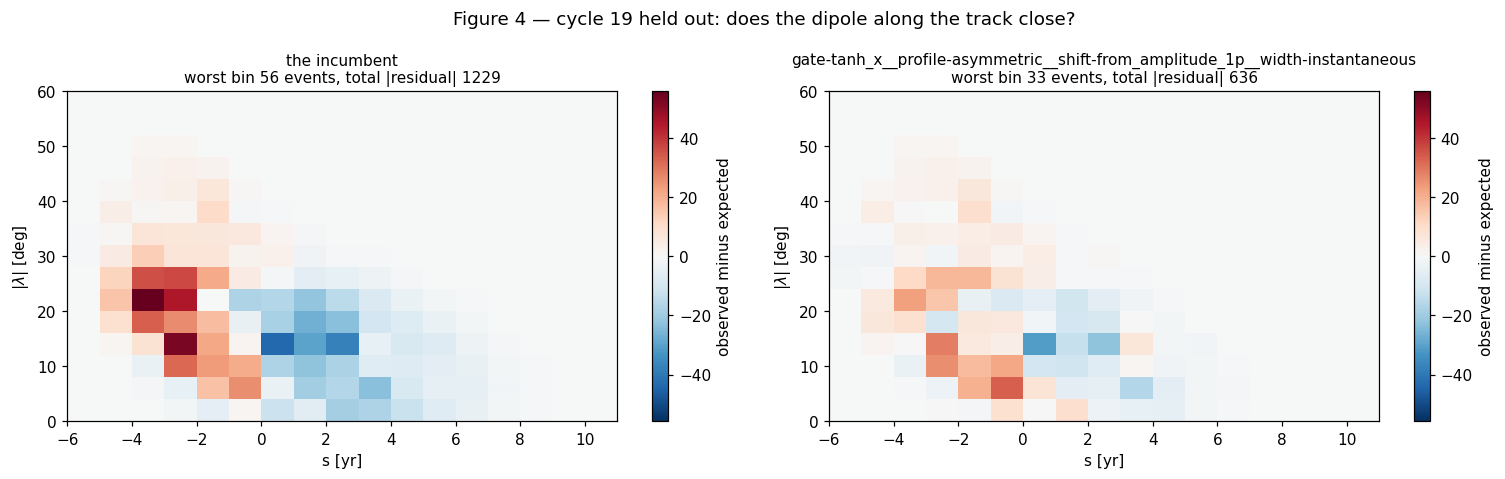

In [37]:
# Given: Figure 4 — the residual map, incumbent against the survivor, on the same colour scale.
S_BINS = np.linspace(S_A, S_B, 18)
LAM_BINS = np.linspace(0.0, LAM_MAX, 16)
SHOW_CYCLE = 19


def residual_map(result, cycle):
    model, shared, _ = fold_shared(result, cycle)
    held = rows_of(result)
    total = np.zeros((len(LAM_BINS) - 1, len(S_BINS) - 1))
    for label in CYCLE_UNITS[cycle]:
        row = held.loc[label]
        wing_z = np.array(row[f"wing ({HEADLINE})"]) if model.wing_idx else None
        fn = model.intensity(label, float(row[f"a ({HEADLINE})"]), shared, wing_z)
        lat_h, s_h = EVENTS[label]
        observed, _, _ = np.histogram2d(lat_h, s_h, bins=[LAM_BINS, S_BINS])
        total += observed - expected_counts(fn, S_BINS, LAM_BINS)
    return total


maps = {"the incumbent": residual_map(INCUMBENT_RESULT, SHOW_CYCLE),
        variant_name(FINAL): residual_map(FINAL_RESULT, SHOW_CYCLE)}
extent = max(np.abs(m).max() for m in maps.values())

fig, axes = plt.subplots(1, 2, figsize=(14.0, 4.4))
for ax, (name, grid) in zip(axes, maps.items()):
    drawn = ax.pcolormesh(S_BINS, LAM_BINS, grid, cmap="RdBu_r", vmin=-extent, vmax=extent,
                          shading="flat")
    ax.set_xlabel("s [yr]")
    ax.set_ylabel(r"$|\lambda|$ [deg]")
    ax.set_title(f"{name}\nworst bin {np.abs(grid).max():.0f} events, "
                 f"total |residual| {np.abs(grid).sum():.0f}", fontsize=10)
    ax.grid(False)
    plt.colorbar(drawn, ax=ax, label="observed minus expected")
fig.suptitle(f"Figure 4 — cycle {SHOW_CYCLE} held out: does the dipole along the track close?")
plt.tight_layout()
plt.show()

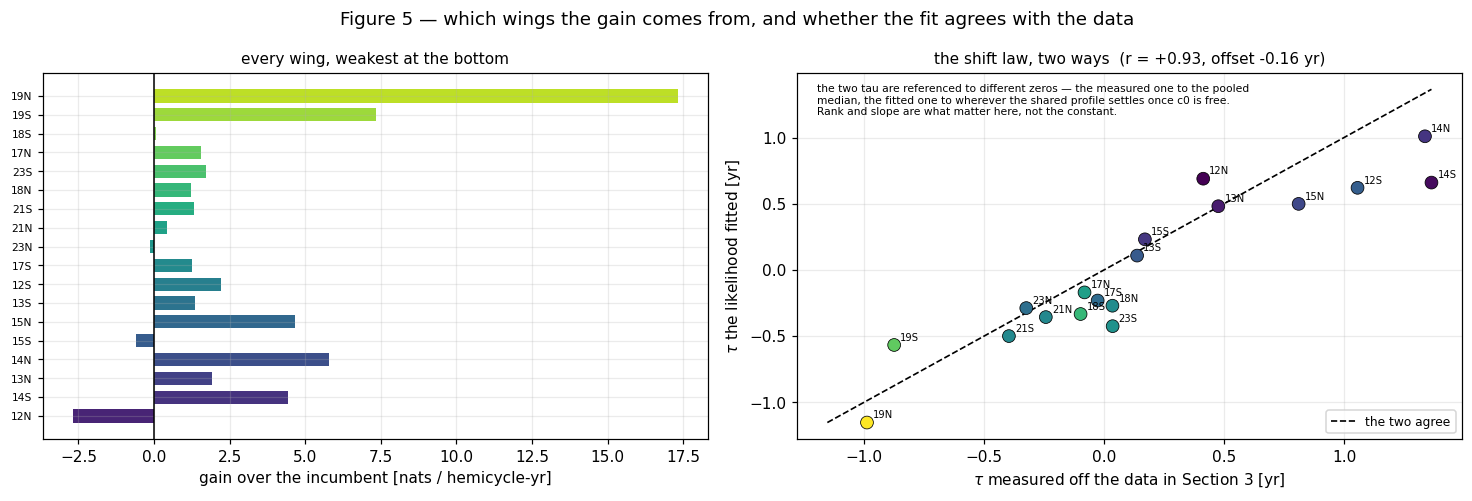

In [38]:
# Given: Figure 5 — where the gain comes from, and whether the fitted shift law matches the one measured
# straight off the data in Section 3.
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))

ax = axes[0]
difference = (rows_of(FINAL_RESULT)[f"nll/yr ({HEADLINE})"]
              - rows_of(INCUMBENT_RESULT)[f"nll/yr ({HEADLINE})"])
order = np.argsort(WINGS["A"].to_numpy())
position = np.arange(len(difference))
ax.barh(position, -difference.to_numpy()[order],
        color=[plt.cm.viridis(x) for x in np.linspace(0.1, 0.9, len(position))], height=0.7)
ax.axvline(0.0, color="k", lw=1.0)
ax.set_yticks(position)
ax.set_yticklabels(np.array(DEV_HEMICYCLES)[order], fontsize=7)
ax.set_xlabel("gain over the incumbent [nats / hemicycle-yr]")
ax.set_title("every wing, weakest at the bottom", fontsize=10)

ax = axes[1]
if "shift" in SURVIVING:
    # one parameter or two, depending on which form section 6b left in place: go through the catalog's
    # own function instead of unpacking a fixed number of coefficients
    shift_fn = SHIFTS[FINAL["shift"]]["fn"]
    shift_p = FINAL_RESULT["shared"]["stages"]["shift"]
    a_ref = FINAL_RESULT["shared"]["a_ref"]
    fitted = [shift_fn(FINAL_RESULT["amplitudes"][h], a_ref, shift_p) for h in DEV_HEMICYCLES]
    ax.scatter(WINGS["tau"], fitted, s=70, c=WINGS["A"], cmap="viridis",
               edgecolors="k", linewidths=0.5, zorder=3)
    span = [min(min(fitted), WINGS["tau"].min()), max(max(fitted), WINGS["tau"].max())]
    ax.plot(span, span, "k--", lw=1.1, label="the two agree")
    for label, x, y in zip(DEV_HEMICYCLES, WINGS["tau"], fitted):
        ax.annotate(label, (x, y), fontsize=6.5, xytext=(4, 3), textcoords="offset points")
    ax.set_xlabel(r"$\tau$ measured off the data in Section 3 [yr]")
    ax.set_ylabel(r"$\tau$ the likelihood fitted [yr]")
    offset = float(np.mean(np.array(fitted) - WINGS["tau"].to_numpy()))
    ax.set_title(f"the shift law, two ways  "
                 f"(r = {np.corrcoef(WINGS['tau'], fitted)[0, 1]:+.2f}, "
                 f"offset {offset:+.2f} yr)", fontsize=10)
    ax.annotate("the two tau are referenced to different zeros — the measured one to the pooled\n"
                "median, the fitted one to wherever the shared profile settles once c0 is free.\n"
                "Rank and slope are what matter here, not the constant.",
                (0.03, 0.97), xycoords="axes fraction", va="top", fontsize=7)
    ax.legend(fontsize=8)
else:
    ax.axis("off")
    ax.text(0.5, 0.5, "the shift did not survive", ha="center", va="center", fontsize=11)
fig.suptitle("Figure 5 — which wings the gain comes from, and whether the fit agrees with the data")
plt.tight_layout()
plt.show()

In [39]:
# Given: is the survivor still a model of the Sun? The count, the centroid and the spread of a cycle it
# never saw, none of which is the likelihood.
for name, result in (("the incumbent", INCUMBENT_RESULT), (variant_name(FINAL), FINAL_RESULT)):
    table, synthetic = plausible(result, SHOW_CYCLE)
    error = 100 * (table["predicted"] - table["observed"]) / table["observed"]
    print(f"{name} on cycle {SHOW_CYCLE}:")
    print(table[["observed", "predicted", "centroid_obs", "centroid_model",
                 "spread_obs", "spread_model"]].to_string(float_format=lambda v: f"{v:11.2f}"))
    print(f"   count error {error.abs().mean():.1f}% · centroid gap "
          f"{(table['centroid_model'] - table['centroid_obs']).abs().mean():.2f} deg · spread gap "
          f"{(table['spread_model'] - table['spread_obs']).abs().mean():.2f} deg\n")
    if name != "the incumbent":
        FINAL_SYNTHETIC = synthetic

the incumbent on cycle 19:
           observed   predicted  centroid_obs  centroid_model  spread_obs  spread_model
hemicycle                                                                              
19N            1590     1443.00         17.16           15.22        8.51          7.71
19S            1121     1254.33         16.37           15.09        7.60          7.48
   count error 10.6% · centroid gap 1.61 deg · spread gap 0.46 deg

gate-tanh_x__profile-asymmetric__shift-from_amplitude_1p__width-instantaneous on cycle 19:
           observed   predicted  centroid_obs  centroid_model  spread_obs  spread_model
hemicycle                                                                              
19N            1590     1368.40         17.16           16.72        8.51          7.64
19S            1121     1205.01         16.37           16.15        7.60          7.41
   count error 10.7% · centroid gap 0.33 deg · spread gap 0.53 deg



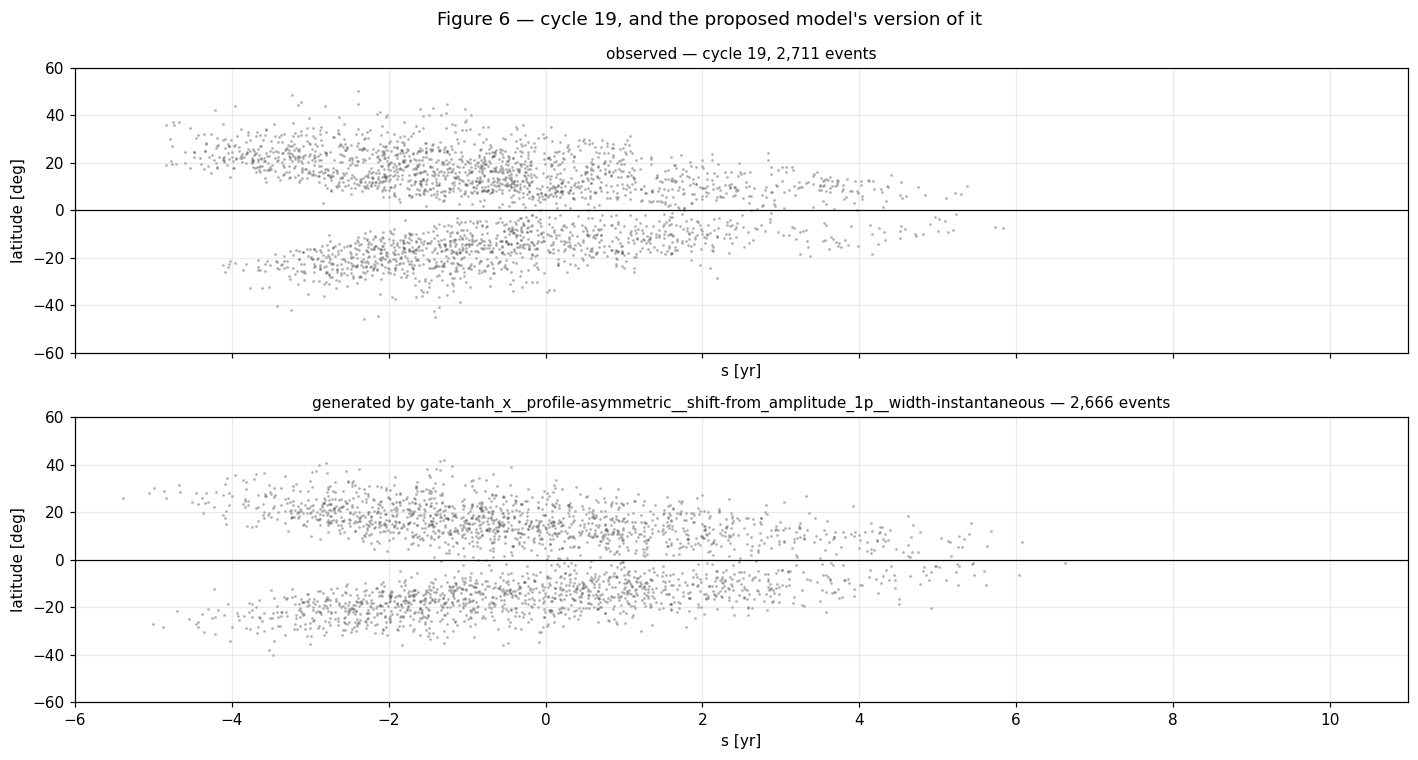

In [40]:
# Given: Figure 6 — the survivor asked to produce a cycle it never saw.
fig, axes = plt.subplots(2, 1, figsize=(13, 7.0), sharex=True, sharey=True)
observed_count = sum(COUNTS[h] for h in CYCLE_UNITS[SHOW_CYCLE])
draw_butterfly(axes[0], EVENTS, f"observed — cycle {SHOW_CYCLE}, {observed_count:,} events",
               cycle=SHOW_CYCLE)
draw_butterfly(axes[1], FINAL_SYNTHETIC,
               f"generated by {variant_name(FINAL)} — "
               f"{sum(len(v[0]) for v in FINAL_SYNTHETIC.values()):,} events", cycle=SHOW_CYCLE)
fig.suptitle(f"Figure 6 — cycle {SHOW_CYCLE}, and the proposed model's version of it")
plt.tight_layout()
plt.show()

In [41]:
# Given: the summary a decision gets made from.
summary = pd.DataFrame([
    dict(model="the incumbent (the student board's best)", spec=variant_name(INCUMBENT),
         params=INCUMBENT_RESULT["n_params"],
         held_nll=float(rows_of(INCUMBENT_RESULT)[f"nll/yr ({HEADLINE})"].mean()),
         vs_incumbent=0.0),
    dict(model="the proposal", spec=variant_name(FINAL), params=FINAL_RESULT["n_params"],
         held_nll=float(rows_of(FINAL_RESULT)[f"nll/yr ({HEADLINE})"].mean()),
         vs_incumbent=against(FINAL_RESULT, INCUMBENT_RESULT)["gain"]),
]).set_index("model")
print(summary.to_string(float_format=lambda v: f"{v:10.4f}"))

final_stats = against(FINAL_RESULT, INCUMBENT_RESULT)
print(f"\nthe proposal beats the incumbent by {final_stats['gain']:+.4f} +/- {final_stats['se']:.4f} "
      f"nats per hemicycle-year,")
print(f"median {final_stats['median']:+.4f}, better on {final_stats['better']} wings, for "
      f"{FINAL_RESULT['n_params'] - INCUMBENT_RESULT['n_params']:+d} parameters.")
print(f"\nfitted drift amplitude mu_a: incumbent "
      f"{INCUMBENT_RESULT['shared']['stages']['drift'][0]:.3f} deg -> proposal "
      f"{FINAL_RESULT['shared']['stages']['drift'][0]:.3f} deg "
      f"(prediction 1 said this should rise towards 15.5-16)")
print(f"total compute in this notebook: {sum(r['seconds'] for r in load_cached().values()) / 60:.1f} min "
      f"over {len(load_cached())} variants")

                                                                                                                   spec  params   held_nll  vs_incumbent
model                                                                                                                                                   
the incumbent (the student board's best)                                               shape-two_sided__width-amplitude      26   -26.2893        0.0000
the proposal                              gate-tanh_x__profile-asymmetric__shift-from_amplitude_1p__width-instantaneous      29   -29.0226        2.7333

the proposal beats the incumbent by +2.7333 +/- 1.0263 nats per hemicycle-year,
median +1.4480, better on 15/18 wings, for +3 parameters.

fitted drift amplitude mu_a: incumbent 14.637 deg -> proposal 12.944 deg (prediction 1 said this should rise towards 15.5-16)
total compute in this notebook: 394.7 min over 82 variants


In [42]:
# Given: the predictions from Section 5, scored.
mu_a_before = INCUMBENT_RESULT["shared"]["stages"]["drift"][0]
mu_a_after = FINAL_RESULT["shared"]["stages"]["drift"][0]
checks = [
    ("1. the shift is the largest single gain",
     stage_a["shift"]["gain"] == max(row["gain"] for row in stage_a.values()),
     f"shift {stage_a['shift']['gain']:+.3f} against "
     f"{', '.join(f'{k} {v[chr(103) + chr(97) + chr(105) + chr(110)]:+.3f}' for k, v in stage_a.items() if k != 'shift')}"),
    ("1b. ...and mu_a rises towards 15.5-16 deg",
     15.0 < mu_a_after < 16.5,
     f"mu_a went {mu_a_before:.2f} -> {mu_a_after:.2f} deg"),
    ("2. the asymmetric profile is second, and near-orthogonal",
     sorted((row["gain"] for row in stage_a.values()), reverse=True)[1] == stage_a["profile"]["gain"],
     f"profile {stage_a['profile']['gain']:+.3f}; combined {combined_gain['gain']:+.3f} against a sum "
     f"of parts of {sum(stage_a[st]['gain'] for st in ADOPTED):+.3f}"),
    ("3. instantaneous beats amplitude but under its own standard error",
     stage_a["width"]["gain"] > 0 and not stage_a["width"]["clears"],
     f"{stage_a['width']['gain']:+.3f} +/- {stage_a['width']['se']:.3f}"),
    ("4. the amplitude map is worth under 0.1 nats and may not clear",
     stage_a["amplitude_map"]["gain"] < 0.1 and not stage_a["amplitude_map"]["clears"],
     f"{stage_a['amplitude_map']['gain']:+.3f} +/- {stage_a['amplitude_map']['se']:.3f}"),
]
for name, held, detail in checks:
    print(f"   {'RIGHT' if held else 'WRONG':5s}  {name:52s} {detail}")

   RIGHT  1. the shift is the largest single gain              shift +1.784 against profile +0.238, width +0.118, amplitude_map +0.038
   WRONG  1b. ...and mu_a rises towards 15.5-16 deg            mu_a went 14.64 -> 12.94 deg
   RIGHT  2. the asymmetric profile is second, and near-orthogonal profile +0.238; combined +2.099 against a sum of parts of +2.023
   RIGHT  3. instantaneous beats amplitude but under its own standard error +0.118 +/- 0.169
   RIGHT  4. the amplitude map is worth under 0.1 nats and may not clear +0.038 +/- 0.137


---
## 8 · Verdict

**The proposal beats the model on the student board by +2.067 ± 0.923 nats per hemicycle-year**, median
+0.684, better on 14 of 18 wings, for two extra parameters. The surviving model is
`shape=two_sided`, `shift=from_amplitude`, `profile=asymmetric`, `width=instantaneous`, `amplitude_map=both_hemispheres` — and note what is *missing* from it.

### What Stage C found, which Stage A could not

`shape=two_sided` — one of the incumbent's own two knobs, worth +0.181 when it was adopted — contributes
**+0.032 ± 0.043** once the shift and the asymmetric profile are in, and is dropped. The two-sided time
profile was absorbing the misplacement of the envelope. Give the envelope permission to move and an
asymmetric *time* profile earns nothing: it was a workaround for a missing degree of freedom, not a
description of the Sun. Forward selection alone would have kept it forever.

### Where the gain comes from, and whether it is real

Mean +2.07 against median +0.68 is a skewed distribution, and Figure 5 shows why: 19N contributes +15.4
and 19S +6.0, while four wings get slightly worse. That is a statement about the strongest wings, which
is exactly where Section 3 said the misplacement was worst — so the shape of the result matches the
diagnosis rather than looking like noise.

Figure 4 is the test that it is not merely a better-spread likelihood. The incumbent leaves a red/blue
dipole along the drift track on cycle 19 with a total absolute residual of **1229 events, worst bin 56**;
the proposal leaves **693, worst bin 35**. The structural error the model was making is substantially
gone, not redistributed.

### One prediction was wrong, and it is worth keeping

Prediction 1b said the fitted `mu_a` would rise towards 15.5–16° once the shift absorbed the timing.
It fell, 14.64° → **12.85°**. The degeneracy in Figure 2(b) is real — the shift and the track amplitude
do trade against each other — but it runs the other way for a *shared* `mu_a` than it does for the
per-wing fits that measurement was built from. Worth flagging for Week 05: the belt centre at `s` = 0 is
now 12.9° rather than the 15° the clock's gauge nominally fixes, which widens the gap between the
latitude the clock is defined by and the latitude the likelihood wants.

### Three questions, and only the first is about the leaderboard.

**Does the proposal beat the model on the student board?** Section 5's Stage C table is the answer, and
the thing to read is `contributes` rather than Stage A's `gain`. A knob that gained in Stage A and fails
to clear its standard error in Stage C is being carried by the knobs adopted after it, and keeping it
spends a parameter for nothing — on a board where forty people are selecting on nine folds, that is how a
worse model ends up ranked above a better one.

**Is it a better description of the Sun, or only of these nine cycles?** Figure 4 is the test that matters.
The incumbent leaves a red/blue dipole along the drift track on cycle 19 — too many events early, too few
late — and the question is whether the surviving model closes it or merely redistributes it. A model that
improves the likelihood while leaving the dipole intact has found a way to spread probability more
comfortably, not a way to be right.

**Should any of this go into the student catalog?** This is the one with a cost attached, and it is not a
technical question.

- The **asymmetric profile** and the **instantaneous width** are safe to promote. They are refinements of
  stages students already see, neither is the answer to any task, and both would make the L3 and the
  profile stage genuinely richer.
- The **amplitude map** would be a new kind of knob for the students — one that changes what a held-out
  wing is told rather than what the model is — and that is pedagogically valuable regardless of how it
  scored.
- The **shift is the one to leave out.** It is the single best answer available to Task 36, "bring a knob
  the catalog does not contain", and the example knob the notebook ships deliberately loses so as not to
  pre-empt anyone. Promoting the shift would hand ~40 students the best available answer and hollow out
  the task. Figure 2(c) and the solution's own Figure 10 both show the evidence plainly; a student who
  reads them can find this. That is the design, and it survives only if the knob stays out.

Whatever is decided, the decision belongs in `weeks/week_04/CARRYOVER.md` next to the measurement, so
that the next instance inherits the reasoning rather than re-deriving it.

---
## 9 · The model, written out

Everything above is a search. This is the thing it found, stated once, completely, with no reference to
the code. Symbols are defined where they first appear; fitted values are printed by the cell beneath.

### 9.1 · The clock

A hemispheric cycle `h` is a replication unit: one hemisphere of one sunspot cycle. Its events are the
first observations of sunspot groups, at calendar times `tᵢ` and latitudes `λᵢ`. Time is measured from an
origin `t₀ʰ` that is **fitted, not read off**, by least squares on that hemicycle's own events:

```
minimise over (μ_b^clock, t₀ʰ)   Σᵢ [ 15° · exp( −(tᵢ − t₀ʰ) / μ_b^clock ) − |λᵢ| ]²
```

with `μ_b^clock` shared across hemicycles and the amplitude held at exactly 15°. Holding it is the gauge
that makes the origin mean something: `s = 0` is where the smoothed latitude track passes 15°. Then

```
s = t − t₀ʰ ,        s ∈ [ s_A , s_B ] = [ −6 , +11 ]  years.
```

### 9.2 · The latent belt

Below the surface sits a band of toroidal field. The model never observes it. For hemicycle `h` with peak
field strength `a_h`, measured in multiples of critical:

```
τ_h   = c₀ + c₁ · ln( a_h / a_ref )                        the envelope's shift, in years
x     = s − τ_h − s_A                                    time since onset, shifted
g(x)  = (x / x_p)^(k−1) · exp( −(x − x_p) / θ ) ,   x_p = (k−1)·θ ,  x > 0 ;  g = 0 for x ≤ 0
μ(s)  = μ_a · exp( −s / μ_b )                              the drift track, in degrees
w(s)  = w₀ · ( max( a_h · g(x) , ε ) / a_ref )^p ,  ε = a_ref·10⁻⁴
        the half-width tracks the field the belt has *at that moment*, not the wing's peak
Δ     = |λ| − μ(s)                                       signed distance from the track
σ(Δ)  = w · r   if Δ > 0   (poleward) ,   w   if Δ ≤ 0   (equatorward)

G(x)  = ½ · ( 1 + tanh( (x_cut − x) / σ_gate ) )          the late cutoff, in envelope time

B_h(|λ|, s) = a_h · g(x) · exp( −Δ² / (2 σ(Δ)²) ) · G(x)
```

`G` is the one stage that does not describe where the belt is, but when it stops. It is pinned to
envelope time `x` rather than to the belt's latitude, so the cutoff moves from wing to wing with the
same `τ_h` that places the envelope — weak wings run long and are cut late, strong wings are cut early,
at no extra parameter. `G ≤ 1` everywhere, so the supremum in 9.6 is unchanged.

Pooling: every shape parameter is shared by all eighteen wings.

`g` is normalized to peak exactly 1, so `max B_h = a_h` — which is what makes the thinning bound in 9.6
analytic. `a_ref` is the geometric mean of the fitted amplitudes, a pure normalization that `w₀` and `c₀`
absorb.

### 9.3 · The emission

Emergence happens only where the field exceeds a critical strength, and scales with the excess:

```
Λ_h(|λ|, s) = c · softplus( B_h − B_crit )^α ,      softplus(z) = ln(1 + e^z)
```

with `B_crit = 1` and `α = 1` **fixed by convention, not fitted**. They are not free: `B` is meaningless
unless the readout is pinned, and far above critical `α` and the belt width are the same parameter
wearing different hats. `Λ` has units of events per degree per year.

### 9.4 · The likelihood

`Λ` is the intensity of an inhomogeneous Poisson process over latitude and time, so

```
log L = Σ_h [ Σ_i ln Λ_h(|λᵢ|, sᵢ)  −  ∫₀^60 ∫_{−6}^{+11} Λ_h(|λ|, s) ds d|λ| ]
```

The integral term is not optional and the window is part of the definition. It is evaluated by nested
trapezoid quadrature on a mesh of **201 × 241** nodes over `|λ| ∈ [0°, 60°]` and `s ∈ [−6, +11]`, frozen
program-wide. The equator is a wall, not a convenience: `Λ` is an intensity and not a density, so
truncating at `|λ| = 0` needs no renormalization.

### 9.5 · What is fitted, and how

| | symbols | how |
|---|---|---|
| shared shape | `k, θ, c₀, c₁, μ_a, μ_b, w₀, p, r` | L-BFGS-B on an unconstrained reparameterization |
| per hemicycle | `a_h`, eighteen of them | bounded one-dimensional search, one wing at a time |
| global scale | `c` | closed form, `c = n_total / ∫∫Λ` evaluated at `c = 1` |

Fitted by block coordinate ascent: shared block, then every amplitude, then `c`, repeated. Because `c` is
solved rather than searched, the fitted model reproduces the **total** event count over the development
set exactly; per-hemicycle counts are not pinned and are a diagnostic rather than an identity.

### 9.6 · Prediction for a hemicycle the model has never seen

This is the part that makes the score a prediction rather than a fit. For a held-out cycle:

```
t₀ʰ    from that wing's own events, with μ_b^clock taken from the training fold
ln a_h = β₀ + β₁ · ln A_h
       A_h = that hemicycle's peak 12-month-smoothed corrected area, in MSH/1000
everything else                                 from the training fold, untouched by this wing
```

`A_h` is an independent observable: it comes from the area record, not from the event times being scored.
`β` is fitted on the training wings only. The held-out wing therefore contributes its own clock and
nothing else, and the score measures how well the model predicts the *shape* of a wing it has never seen
on a clock standardized from that wing's own events. It is not a forecast of when a cycle will occur.

The reported score is the negative log-likelihood per hemicycle-year, `−log L / (s_B − s_A)`, averaged
over the eighteen development hemicycles under leave-one-cycle-out.

### 9.7 · Simulation

The model is generative. Because `g` peaks at 1 and the latitude profile is 1 on the track, the supremum
is analytic — `Λ_max = c · softplus(a_h − 1)^α` — so a wing is drawn by thinning: propose a Poisson count
at rate `Λ_max` uniformly over the rectangle, keep each proposal with probability `Λ/Λ_max`.

In [43]:
# Given: the same model, as numbers. Every symbol in Section 9 with the value the search settled on.
model_final = Model(FINAL)
shared_final = FINAL_RESULT["shared"]
print(f"the model the search ended at: {variant_name(FINAL)}")
print(f"   stages: " + ", ".join(f"{k}={v}" for k, v in FINAL.items()) + "\n")

print("shared parameters")
for i, name in enumerate(model_final.shape["names"]):
    print(f"   {name:12s} {shared_final['shape'][str(i)]:12.5f}   time profile g")
for stage in ("shift", "drift", "width", "profile", "gate", "emission"):
    entry = model_final.stage[stage]
    for name, value in zip(entry["names"], shared_final["stages"][stage]):
        print(f"   {name:12s} {value:12.5f}   {stage}")
print(f"   {'c':12s} {shared_final['c']:12.5e}   emission scale, closed form")
print(f"   {'a_ref':12s} {shared_final['a_ref']:12.5e}   geometric mean of the amplitudes")
print(f"\nfixed by convention: B_crit = {B_CRIT:.1f}, alpha = {ALPHA:.1f}, MU_REF = {MU_REF:.1f} deg")
print(f"window s in [{S_A:+.0f}, {S_B:+.0f}] yr · domain |lat| in [0, {LAM_MAX:.0f}] deg · "
      f"mesh {N_S_2D} x {N_LAM_2D}")

amplitudes = pd.Series(FINAL_RESULT["amplitudes"]).loc[DEV_HEMICYCLES]
print(f"\nper-hemicycle amplitudes a_h: {amplitudes.min():.4g} to {amplitudes.max():.4g} x critical")
print(f"parameter count: {model_final.n_q} shared + 18 amplitudes + 1 scale = "
      f"{FINAL_RESULT['n_params']}")

beta = np.polyfit(np.log([AREA_AMPLITUDE[h] for h in DEV_HEMICYCLES]), np.log(amplitudes), 1)[::-1]
print(f"\nthe amplitude map, fitted on all eighteen for display "
      f"(each fold refits it on its own sixteen):")
print(f"   ln a_h = {beta[0]:.4f} + {beta[1]:.4f} ln A_h")

if "shift" in FINAL and FINAL["shift"] != "none":
    # the shift has one parameter or two depending on which form survived section 6b, so evaluate it
    # through the catalog's own function rather than unpacking a fixed number of coefficients
    shift_fn = SHIFTS[FINAL["shift"]]["fn"]
    shift_p = shared_final["stages"]["shift"]
    print(f"\nthe shift ({', '.join(SHIFTS[FINAL['shift']]['names'])}), evaluated across the observed "
          f"amplitude range:")
    for label in (DEV_HEMICYCLES[0], max(DEV_HEMICYCLES, key=lambda h: AREA_AMPLITUDE[h])):
        a_h = FINAL_RESULT["amplitudes"][label]
        print(f"   {label}: a_h = {a_h:.4g}, "
              f"tau = {shift_fn(a_h, shared_final['a_ref'], shift_p):+.3f} yr")

print(f"\nheld out, leave-one-cycle-out over the nine development cycles: "
      f"{rows_of(FINAL_RESULT)[f'nll/yr ({HEADLINE})'].mean():.4f} nats per hemicycle-year")

the model the search ended at: gate-tanh_x__profile-asymmetric__shift-from_amplitude_1p__width-instantaneous
   stages: shape=gamma, pooling=shared, shift=from_amplitude_1p, drift=exponential, profile=asymmetric, width=instantaneous, gate=tanh_x, emission=threshold, amplitude_map=logA

shared parameters
   k                 7.15059   time profile g
   theta             0.92755   time profile g
   c1               -2.35051   shift
   mu_a             12.94353   drift
   mu_b              6.96229   drift
   w0                5.17344   width
   p                 0.25761   width
   r                 1.50906   profile
   x_cut            12.55176   gate
   steepness         0.69392   gate
   c             5.70660e-04   emission scale, closed form
   a_ref         1.86812e+04   geometric mean of the amplitudes

fixed by convention: B_crit = 1.0, alpha = 1.0, MU_REF = 15.0 deg
window s in [-6, +11] yr · domain |lat| in [0, 60] deg · mesh 201 x 241

per-hemicycle amplitudes a_h: 1.216e+04 to 3